In [1]:
import pandas as pd 
import os 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

# segmentaçao 
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, davies_bouldin_score)
# testes estatisticos 
import scipy.stats as stats 
# filtro de warnings 
import warnings
warnings.filterwarnings('ignore')

In [2]:
# classes e funçoes auxiliares 
# classe para plot de distribuiçoes
class PlotDistribution():
    def cat_plot(self, data:pd.DataFrame, cat_data):
        if isinstance(data[cat_data], pd.Series):
            print(f'plotando Coluna: {cat_data}')
            plt.figure(figsize=(12,8))
            plt.title(f'{cat_data}')
            ax1 = sns.countplot(data[cat_data], palette='viridis')
            for container in ax1.containers:
                ax1.bar_label(container, fontsize=10)
            plt.xlabel('Contagem')
            plt.tight_layout()
            plt.show()
            
        if isinstance(cat_data, list):
            fig, axes = plt.subplots(figsize=(16, 7 * len(cat_data)), ncols=1, nrows=len(cat_data))
            for cat, ax in zip(cat_data, axes):
                ax1 = sns.countplot(x=data[cat], ax=ax, palette='viridis')
                ax.set_ylabel('Contagem')
                ax.set_title(f'{cat}')
                ax.tick_params(axis='x', rotation=90)
                for container in ax1.containers:
                    ax1.bar_label(container, fontsize=10)
            plt.tight_layout()
            plt.show()
        else:
            print(f'Inpute uma tabela ou uma Serie válida')
            
    def num_plot(self, data: pd.DataFrame, num_data):
        if isinstance(data[num_data], pd.Series):
            fig, axes = plt.subplots(figsize=(16, 3.5 * len(data)), ncols=2, nrows=1)
            sns.boxplot(x=data[num_data], ax=axes[0], fill=False, color='black')
            sns.histplot(data[num_data], kde=True, ax=axes[1], color='blue')
            axes[0].set_title(f'Boxplot - {num_data}')
            axes[1].set_title(f'Histograma - {num_data}')
            fig.tight_layout()
            fig.show()
        if isinstance(num_data, list):
            fig, axes = plt.subplots(figsize=(24,30), ncols=2, nrows=len(num_data))
            for i, num in enumerate(num_data):
                sns.boxplot(x=data[num], ax=axes[i,0], fill=False, color='black')
                sns.histplot(data[num], ax=axes[i,1], kde=True,color='blue')
                axes[i,0].set_title(f'BoxPlot - {num}')
                axes[i,1].set_title(f'Histograma - {num}')
            fig.tight_layout()
            fig.show()
        else:
            print(f'Inpute uma tabela ou uma Serie válida')

# carregar tabelas da base
class LoadSQLTable():
    def __init__(self, con=os.path.join('..', 'src', 'analytics', 'CreditDatabase.db')):
        self.con = sqlite3.connect(con)
    def load_cadastro(self):
        return pd.read_sql_query("SELECT * FROM tabela_cadastral_tratada", self.con)
    def load_emprestimos(self):
        return pd.read_sql_query("SELECT * FROM tabela_emprestimos_tratada", self.con)
    def load_parcelas(self):
        return pd.read_sql_query("SELECT * FROM tabela_parcelas", self.con)

# kde plot
def kde_plot(data:pd.DataFrame, hue:str):
    num_cols = data.select_dtypes(include='number')
    fig, axes = plt.subplots(nrows=len(num_cols.columns)-1, ncols=1, figsize=(16, 3.5 * len(num_cols.columns)))
    for ax, num in zip(axes, num_cols.columns):
        if num != hue:
            sns.kdeplot(data=data, x=num, hue=hue, ax=ax)
            ax.set_title(f'{num}')
    fig.tight_layout()
    fig.show()

# hue boxplot
def boxplot_hue(data:pd.DataFrame, col:str, hue:str):
    if not isinstance(hue, str):
        raise ValueError('escolha uma coluna validaa')
    plt.figure(figsize=(12,8))
    plt.title(f'{col} por {hue}')
    sns.boxplot(data=data, x=col, y=hue)
    plt.tight_layout()
    plt.show()

# classe para plotar graficos agrupados
class PlotGroupby():
    def __init__(self, data:pd.DataFrame, col1:str, col2:str, title:str):
        """"title: na média estara, por exemplo, média entre ....", voce completa"""
        self.data = data
        self.col1 = col1
        self.col2 = col2
        self.title = title
    def plot_mean(self):
        group = self.data.groupby(self.col1)[self.col2].mean()
        fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(20,10))
        axes[0].set_title(f'Média entre {self.title}')
        sns.barplot(group, palette='viridis', ax=axes[0])
        axes[0].tick_params(axis='x', rotation=90)    
        group2 = self.data.groupby(self.col1)[self.col2].sum()
        axes[1].set_title(f'Valores totais {self.title}')
        sns.barplot(group2, palette='viridis', ax=axes[1])
        axes[1].tick_params(axis='x', rotation=90)
        fig.tight_layout()
        fig.show()
        print(f'desvio padrao: {group.std()}')
        print(f'mediana: {group.median()}')
        return pd.DataFrame(group).T
    def groupby_plot_bar(self, group:str):
        agg_data = self.data.groupby([f'{self.col1}', f'{self.col2}'])[f'{group}']
        print(agg_data.mean())
        agg_data.count().unstack(level=0).plot(kind='bar', figsize=(20,10), stacked=True, colormap='viridis', title=self.title)
        
        #mapa de calor 
        plt.figure(figsize=(20,15))
        plt.title(f'Média {self.col1} e {self.col2}')
        sns.heatmap(agg_data.mean().unstack(level=1), cmap='inferno', annot=True, fmt='.2f', cbar_kws={'label': f'Contagem de {group}'})
        plt.tight_layout()
        plt.show()
# funçao para carregar query
def read_load_query(query_path:str):
    con_path = os.path.join('..', 'src', 'analytics', 'CreditDatabase.db')
    con = sqlite3.connect(con_path)
    if not os.path.exists(query_path):
        raise ValueError('query nao encontrada')
    with open(query_path) as f:
        query = f.read()
    return pd.read_sql_query(query, con)

# Carregando base cadastral 

In [3]:
df_cad = LoadSQLTable().load_cadastro()
df_cad = df_cad.set_index('id_cliente')
df_cad.shape

(49589, 15)

In [4]:
# separando em tipos 
num_col_cad = df_cad.select_dtypes(include='number').columns
cat_col_cad = df_cad.select_dtypes(exclude='number').columns

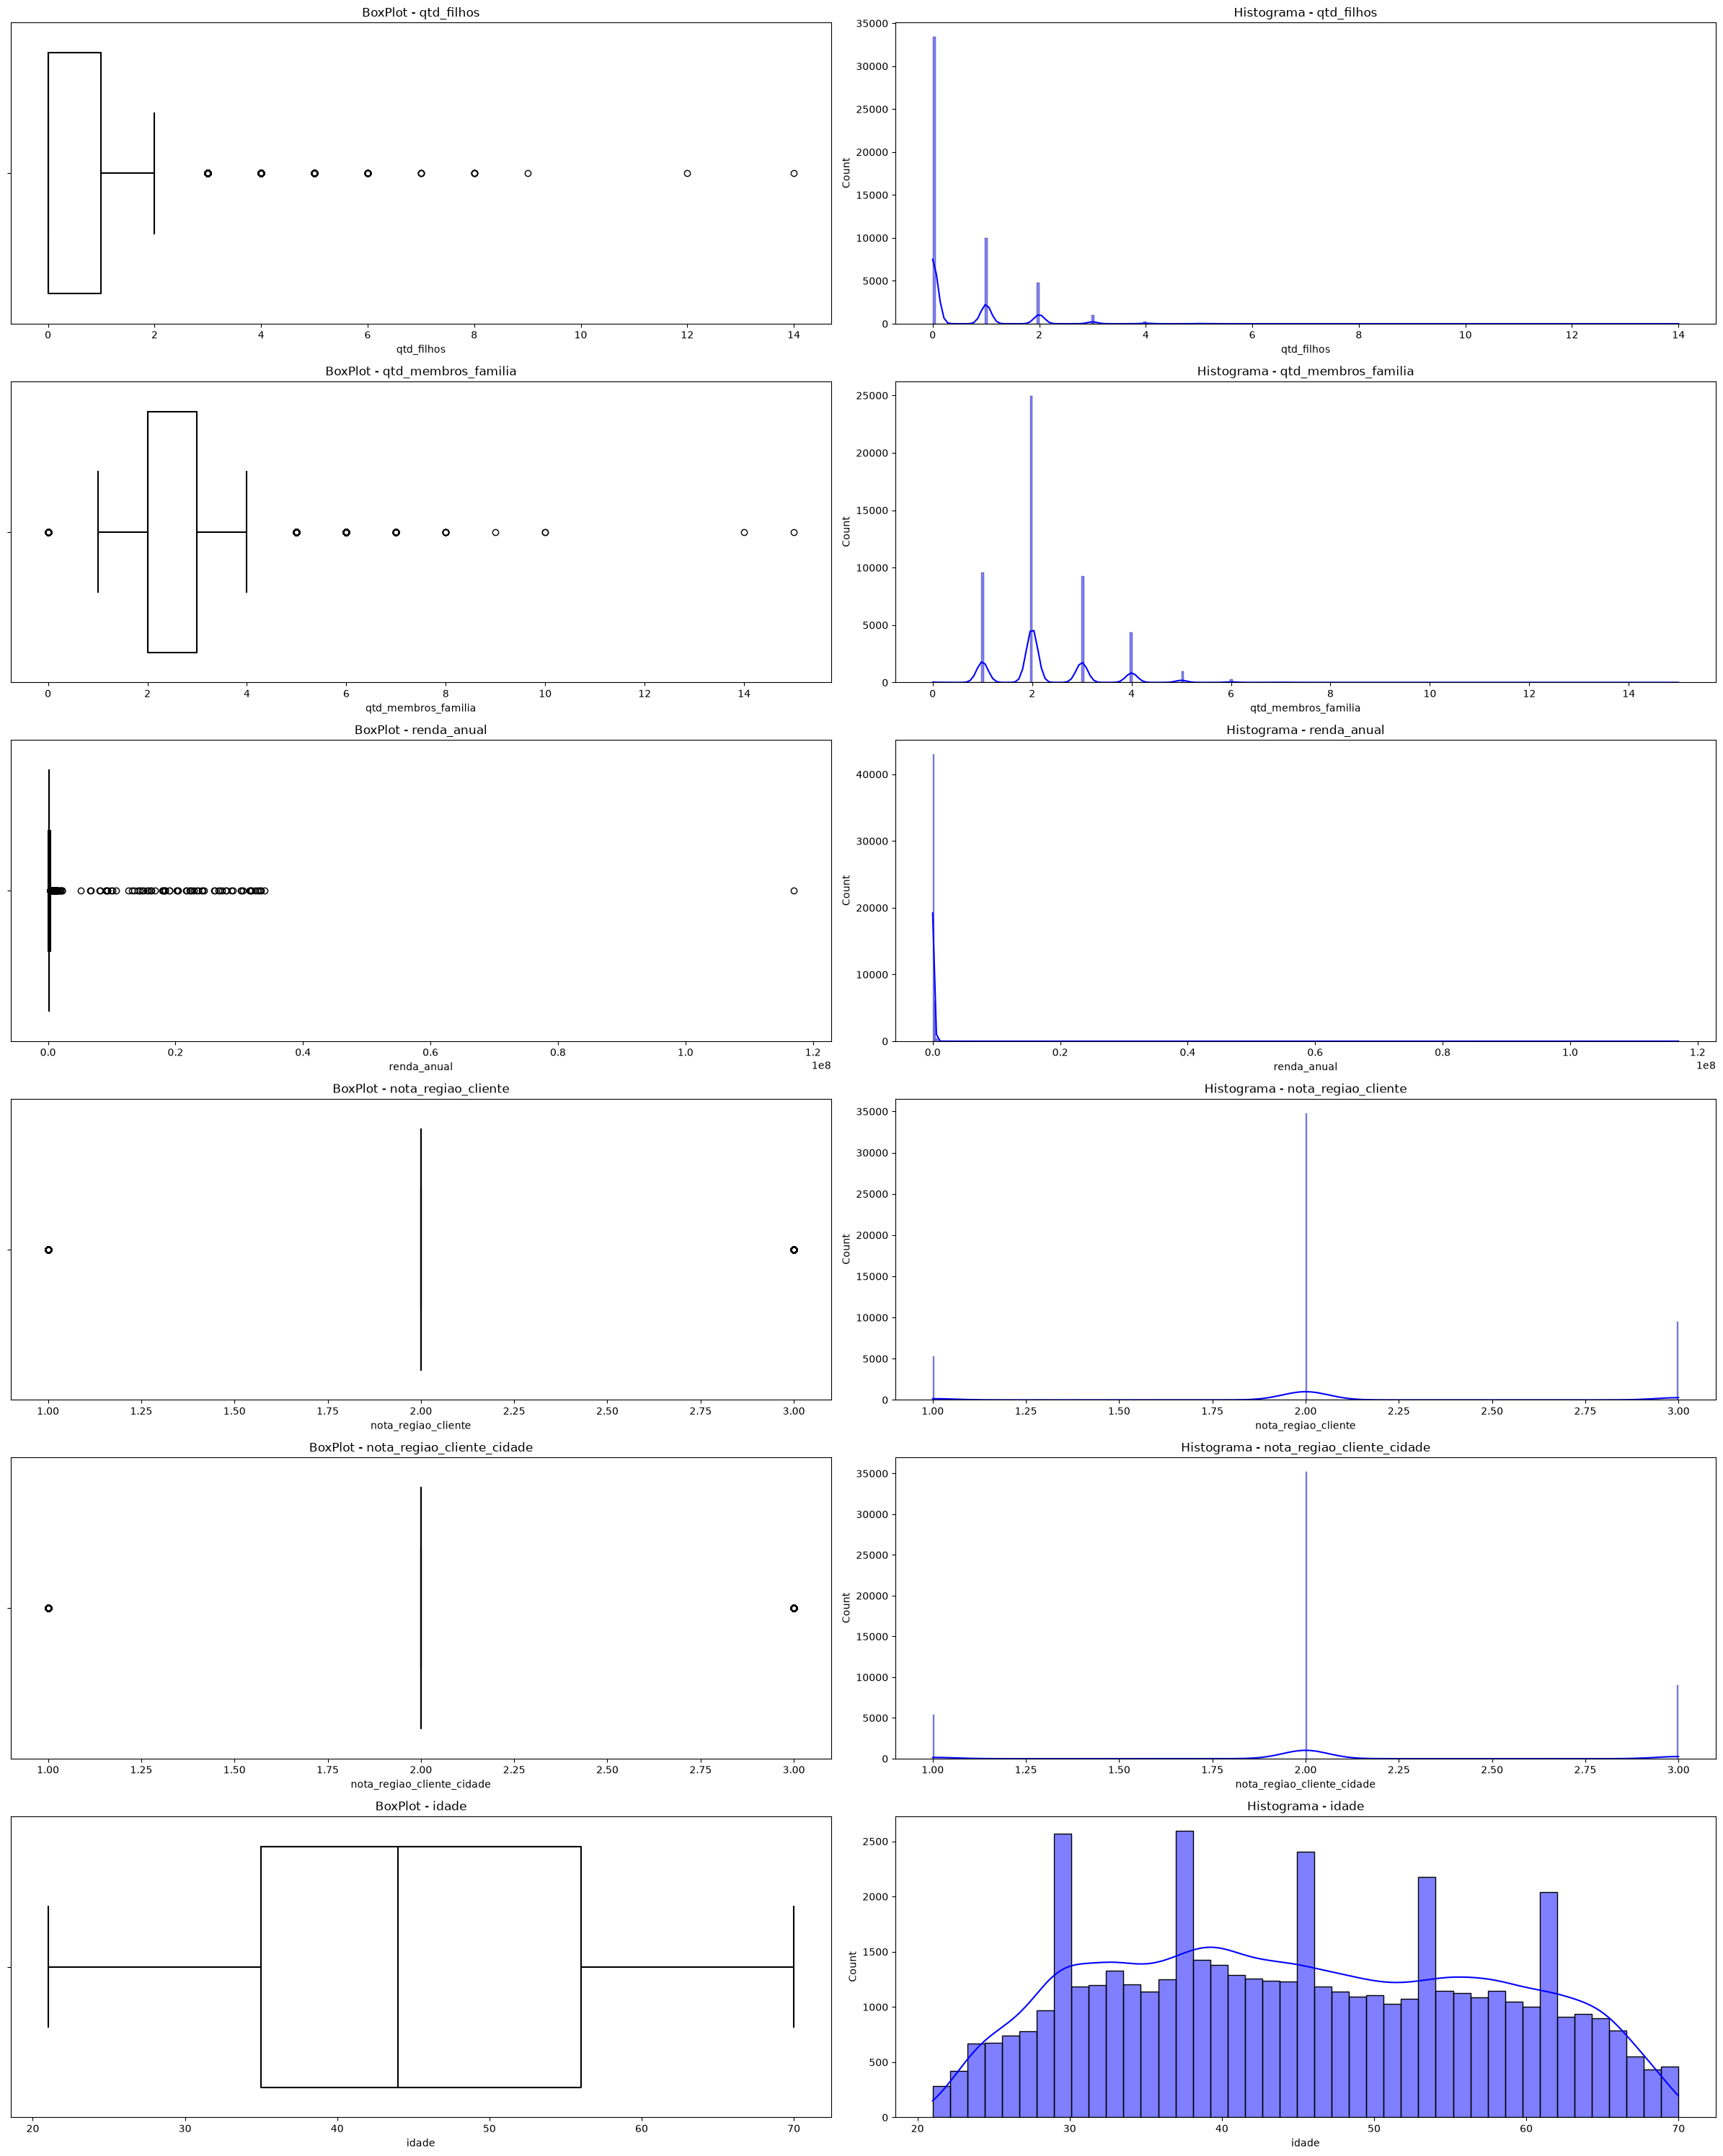

In [5]:
# distribuçao de variaveis numéricas 
PlotDistribution().num_plot(df_cad, list(num_col_cad))

In [6]:
df_cad.describe().T

,count,mean,std,min,25%,50%,75%,max
qtd_filhos,49589.0,0.490996,0.837041,0.0,0.0,0.0,1.0,14.0
qtd_membros_familia,49589.0,2.255904,0.993146,0.0,2.0,2.0,3.0,15.0
renda_anual,49589.0,200484.187173,976993.824090,0.0,112500.0,148500.0,202500.0,117000000.0
nota_regiao_cliente,49589.0,2.083930,0.539717,1.0,2.0,2.0,2.0,3.0
nota_regiao_cliente_cidade,49589.0,2.072314,0.533856,1.0,2.0,2.0,2.0,3.0
idade,49589.0,45.140031,12.374053,21.0,35.0,44.0,56.0,70.0


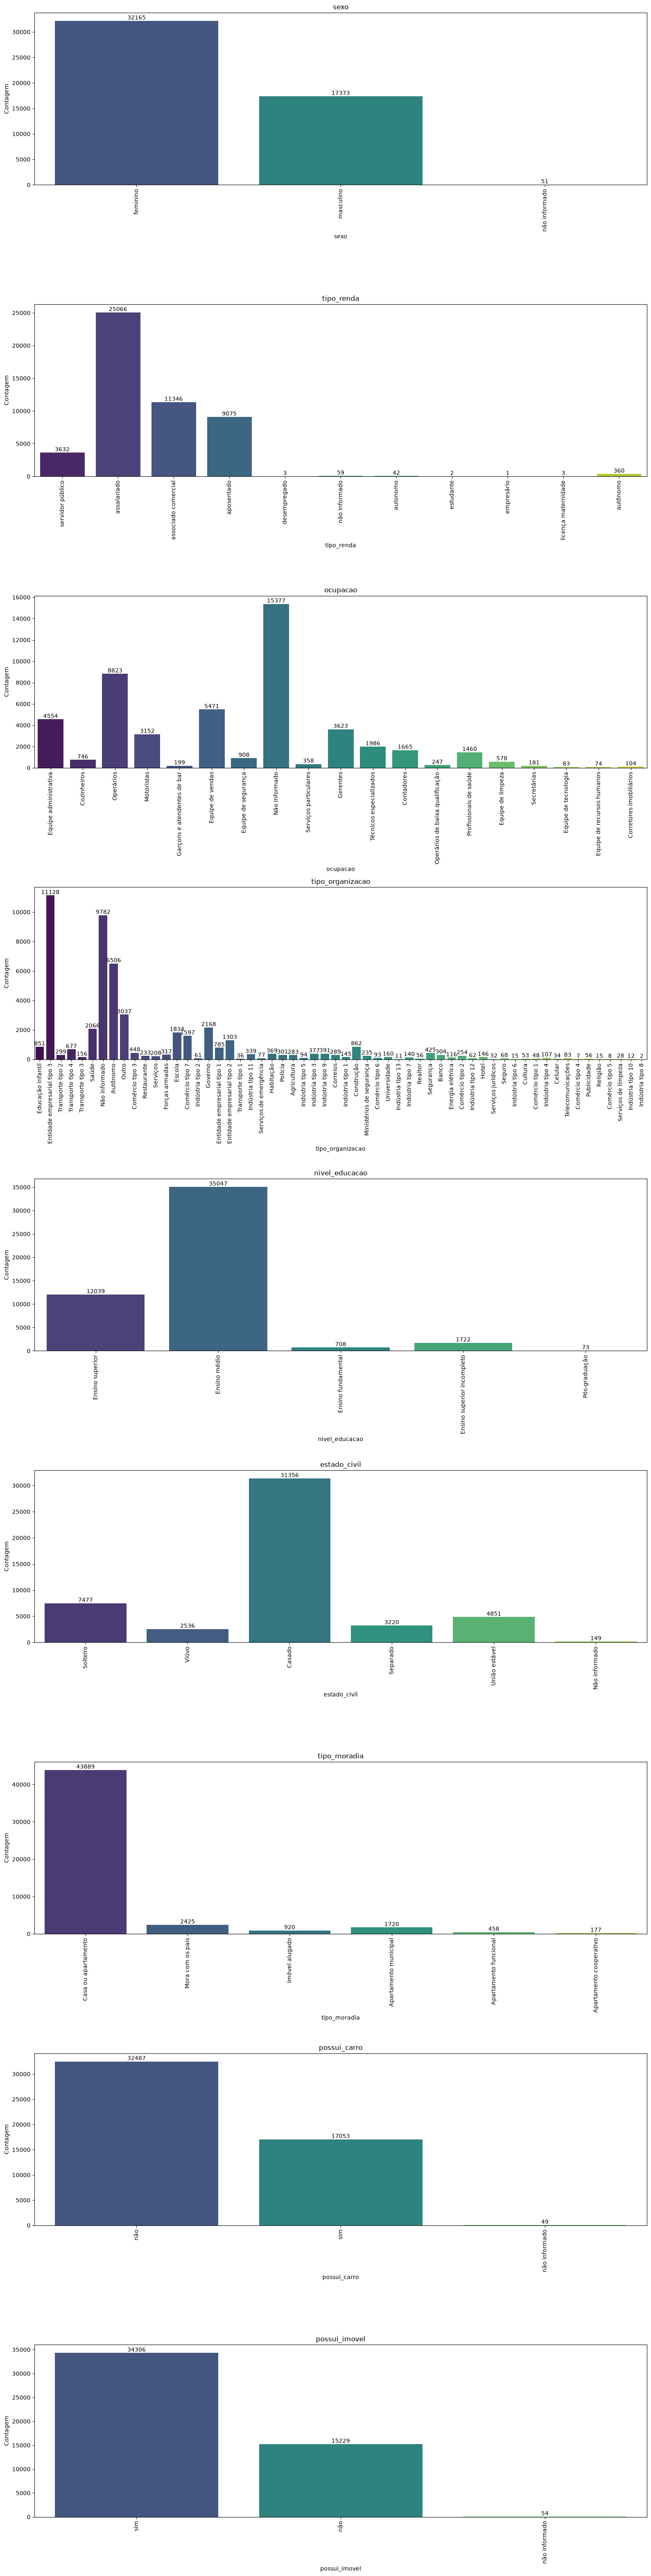

In [7]:
PlotDistribution().cat_plot(df_cad, list(cat_col_cad))

In [8]:
# verificando quantidade de filhos por sexo e ocupaçao
df_cad.groupby(['sexo', 'ocupacao'])['qtd_filhos'].agg(['mean', 'std', 'min', 'max', 'count']).sort_values('mean')

mean       std  min  max  \
sexo          ocupacao                                                        
não informado Equipe de recursos humanos       0.000000       NaN    0    0   
              Técnicos especializados          0.000000  0.000000    0    0   
              Serviços particulares            0.000000       NaN    0    0   
              Secretárias                      0.000000       NaN    0    0   
              Equipe de vendas                 0.000000  0.000000    0    0   
              Equipe de segurança              0.000000       NaN    0    0   
              Contadores                       0.000000       NaN    0    0   
feminino      Equipe de tecnologia             0.181818  0.501081    0    2   
masculino     Secretárias                      0.181818  0.404520    0    1   
              Equipe de limpeza                0.191489  0.495120    0    2   
não informado Equipe administrativa            0.200000  0.447214    0    1   
feminino      Não informado                    0.284943  0.694718    0    7   
              Equipe de segurança              0.303371  0.661585    0    3   
              Equipe de limpeza                0.323917  0.650524    0    4   
não informado Gerentes                         0.333333  0.577350    0    1   
masculino     Garçons e atendentes de bar      0.392857  0.685257    0    2   
              Equipe de recursos humanos       0.400000  0.547723    0    1   
não informado Não informado                    0.400000  0.753937    0    2   
masculino     Cozinheiros                      0.438356  0.745101    0    3   
              Equipe de segurança              0.442188  0.748353    0    6   
              Operários de baixa qualificação  0.444444  0.809864    0    5   
              Corretores imobiliários          0.444444  0.726483    0    2   
              Não informado                    0.455218  0.851096    0    8   
feminino      Equipe de recursos humanos       0.470588  0.679565    0    3   
              Garçons e atendentes de bar      0.473684  0.753937    0    5   
não informado Profissionais de saúde           0.500000  0.707107    0    1   
masculino     Serviços particulares            0.500000  0.894427    0    3   
feminino      Cozinheiros                      0.505201  0.775587    0    4   
              Serviços particulares            0.521994  0.733816    0    3   
              Gerentes                         0.522306  0.847960    0    6   
masculino     Equipe de tecnologia             0.524590  0.993421    0    6   
              Motoristas                       0.533202  0.839157    0   14   
não informado Operários                        0.545455  0.522233    0    1   
feminino      Técnicos especializados          0.545817  0.812146    0    5   
masculino     Operários                        0.546697  0.847620    0    8   
feminino      Corretores imobiliários          0.547368  0.795846    0    3   
              Equipe de vendas                 0.554715  0.870291    0    9   
              Contadores                       0.560678  0.829951    0    5   
masculino     Técnicos especializados          0.561043  0.854476    0    6   
feminino      Profissionais de saúde           0.565523  0.871527    0    8   
              Operários                        0.595782  0.897456    0    8   
masculino     Profissionais de saúde           0.602273  0.938568    0    5   
              Equipe administrativa            0.614853  0.919502    0    6   
feminino      Equipe administrativa            0.624595  0.897573    0   12   
masculino     Gerentes                         0.630769  0.894173    0    6   
feminino      Secretárias                      0.633136  0.783971    0    3   
masculino     Equipe de vendas                 0.634774  0.947295    0    5   
feminino      Operários de baixa qualificação  0.675000  1.095152    0    4   
              Motoristas                       0.716639  1.068034    0    6   
masculino     Contador

- Podemos observar um desvio maior entre ocupaçao dos clientes, ambos apresentam uma quantidade média de filhos inferior a 1
- contadores do sexo masculino apresentam média de aproximadamente 0,80 filho, enquanto mulheres da equipe de tecnologia apresentam 0,18
- Há clientes com quantidades de filhos muito acima da média 
- Há também poucas amostras em alguns grupos, o que limita a inferência


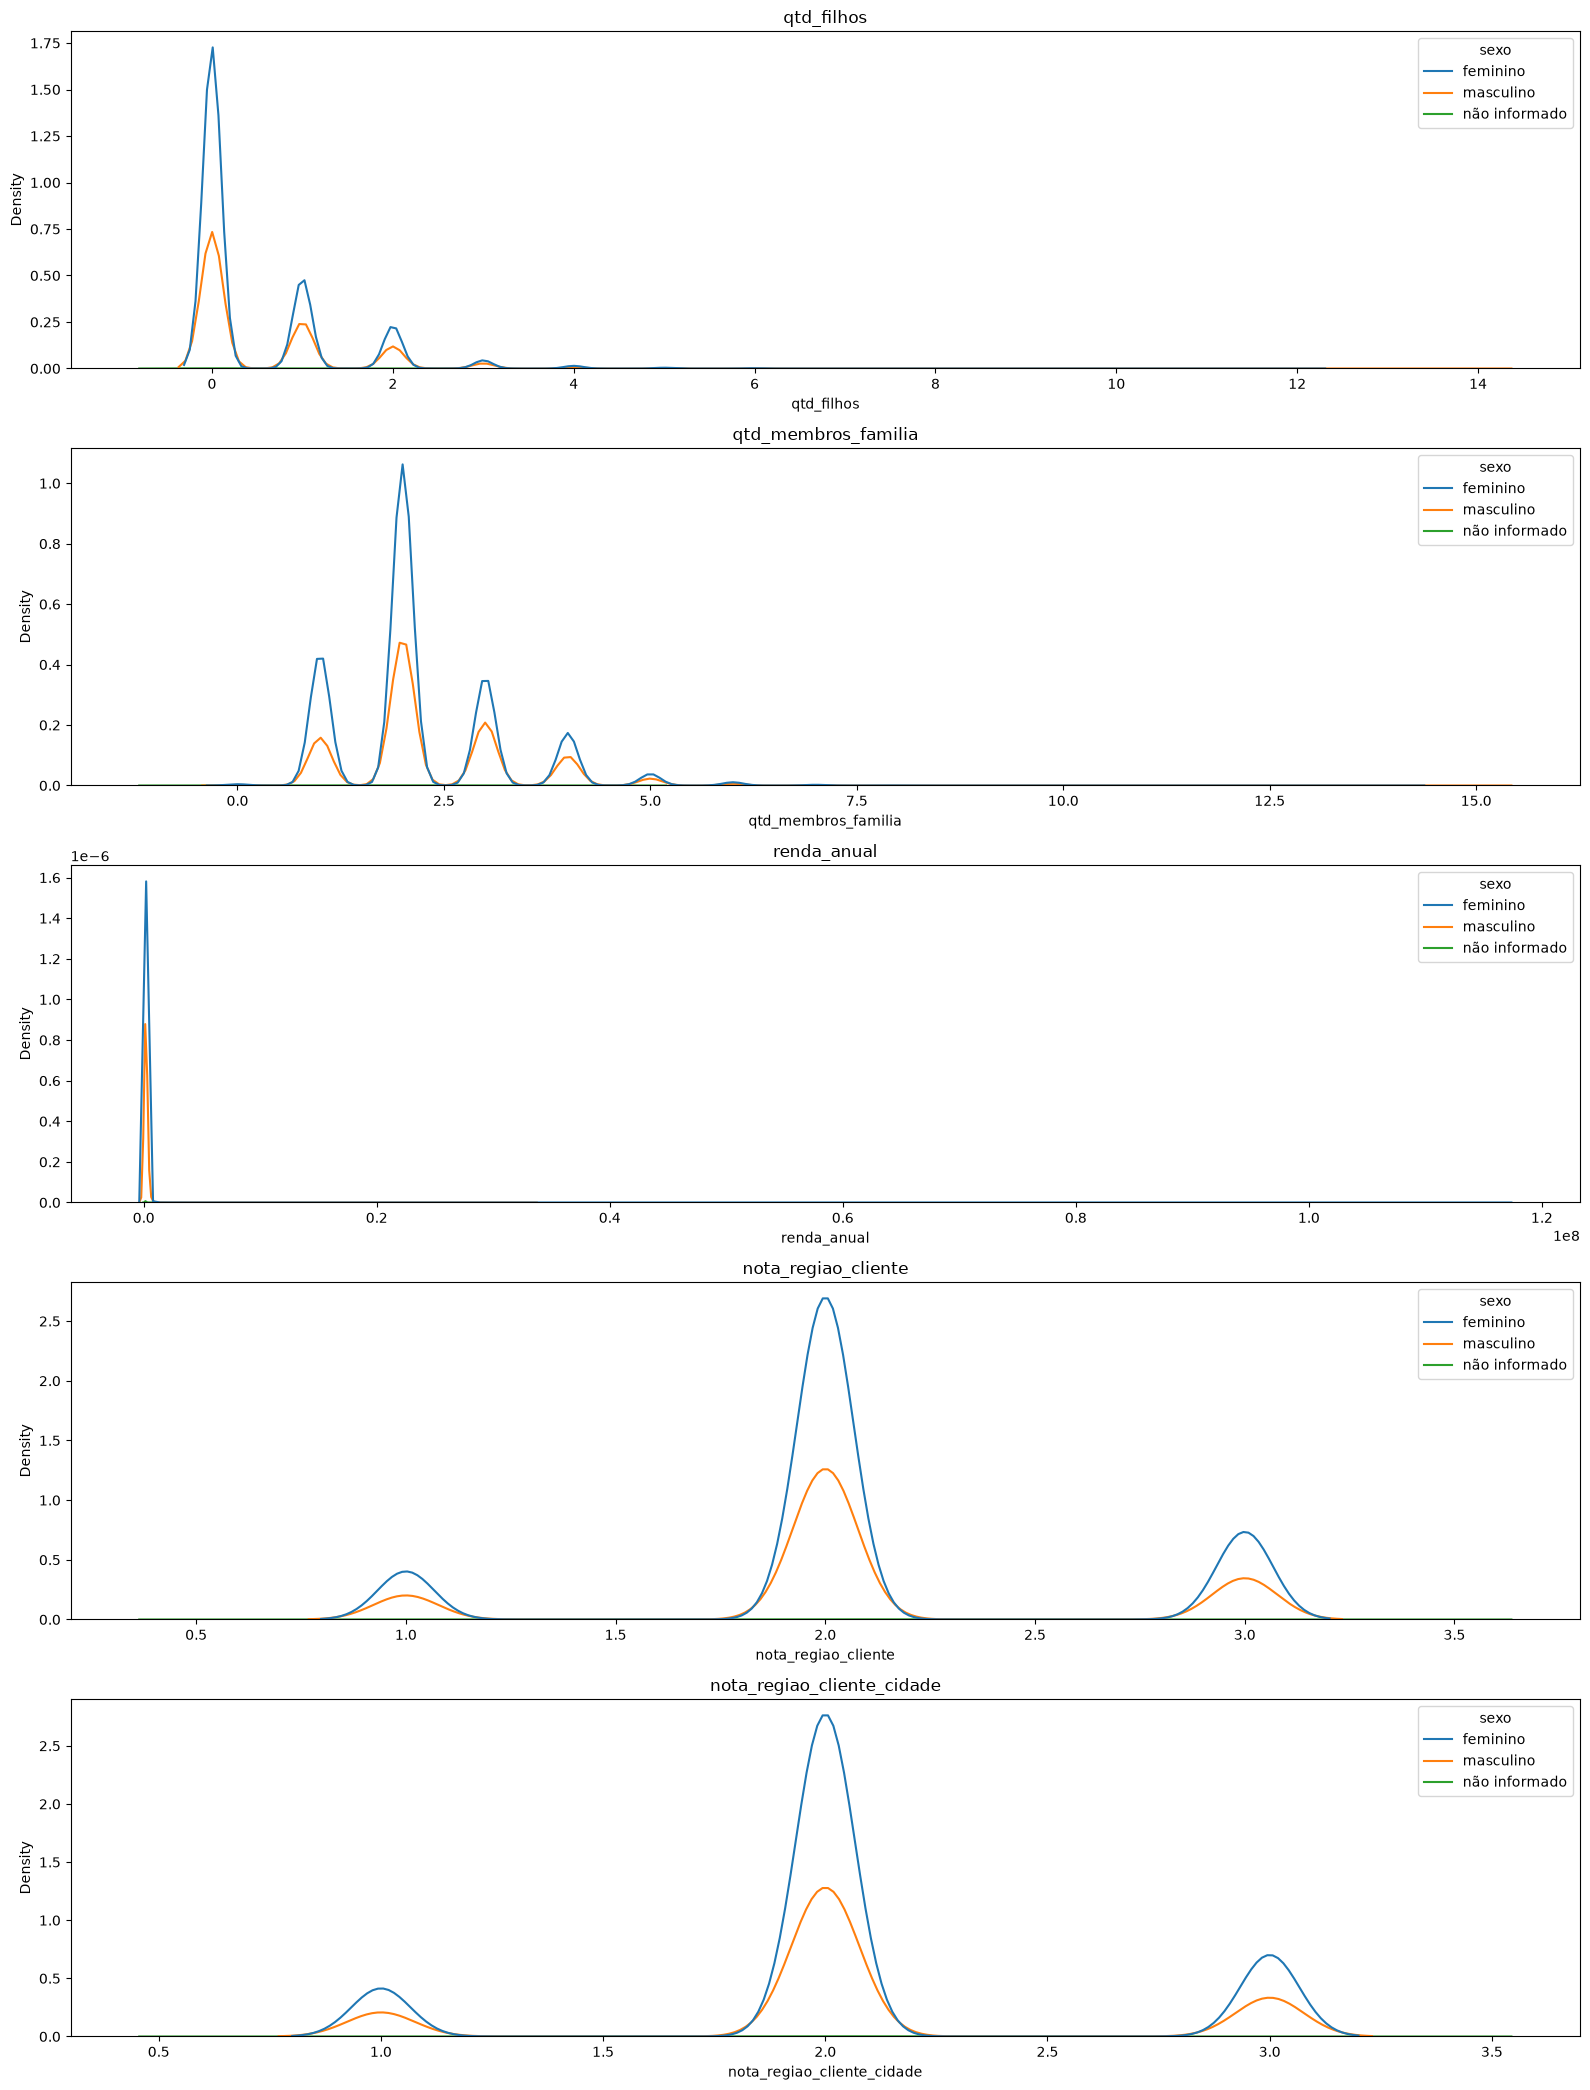

In [9]:
# densidade do sexo nas demais colunas numericas
kde_plot(df_cad, 'sexo')

- A maior parte dos clientes possuem renda normal
- Homens tendem a ter maior numero de filhos e membros da familia

In [10]:
# verificando nivel educacional por sexo e como isso afeta a renda anual 
df_cad.groupby(['sexo', 'nivel_educacao'])['renda_anual'].agg(['mean', 'std', 'count']).sort_values(['mean'], ascending=False)

mean           std  count
sexo          nivel_educacao                                                
masculino     Ensino superior             282792.990138  1.212359e+06   4069
              Ensino superior incompleto  208105.195199  1.154026e+05    679
              Ensino médio                205035.881310  8.147322e+05  12321
feminino      Ensino superior             203671.762880  6.133530e+05   7958
não informado Ensino superior             186041.666667  1.556307e+05     12
masculino     Pós-graduação               185444.736842  1.115188e+05     38
feminino      Ensino médio                184721.129450  1.148760e+06  22689
              Pós-graduação               183600.000000  1.525706e+05     35
              Ensino superior incompleto  171747.376628  3.189058e+05   1041
masculino     Ensino fundamental          159376.155188  9.949642e+04    266
não informado Ensino médio                156813.513514  5.578683e+04     37
feminino      Ensino fundamental          155332.552602  4.439002e+05    442
não informado Ensino superior incompleto  135000.000000  3.181981e+04      2

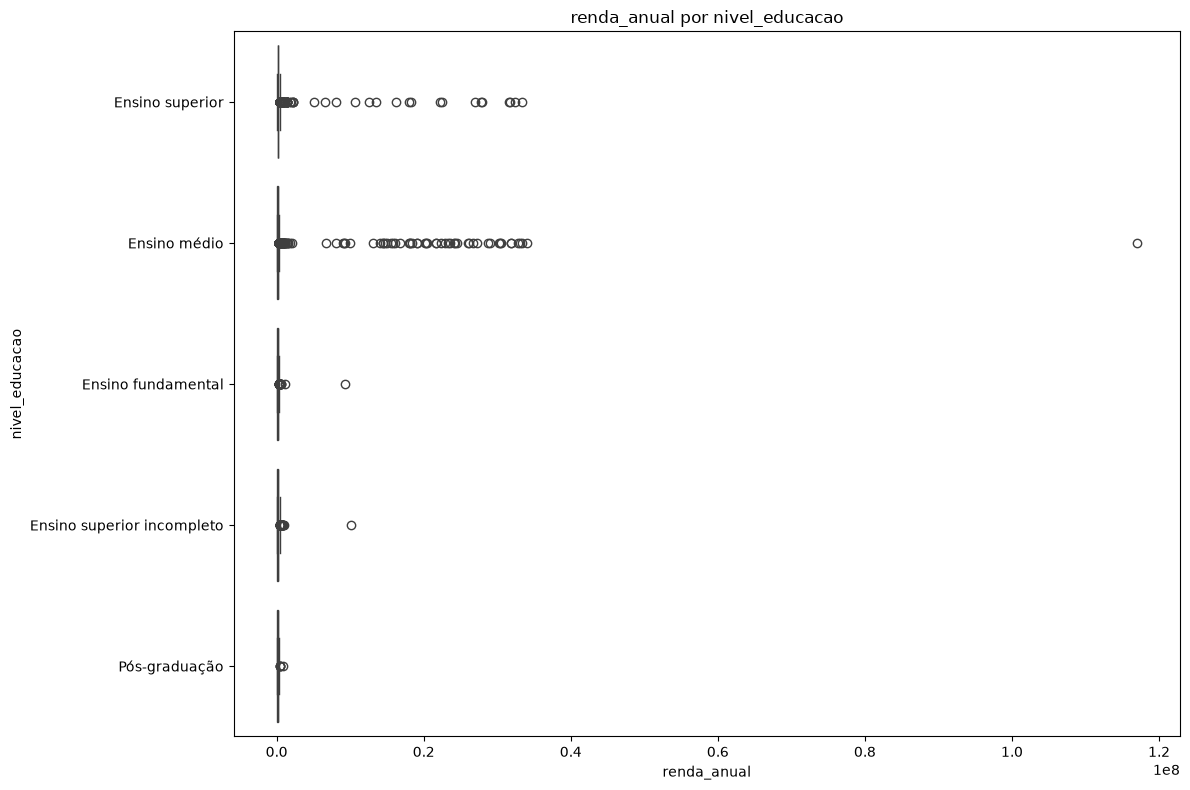

In [11]:
# grafico de nivel de educaçao e renda anual
boxplot_hue(df_cad, 'renda_anual','nivel_educacao')

- O grupo com maior média salarial é o sexo masculino com superior completo, em seguida homens com superior incompleto
- O grupo feminino com superior completo aparece logo em seguida com média menor

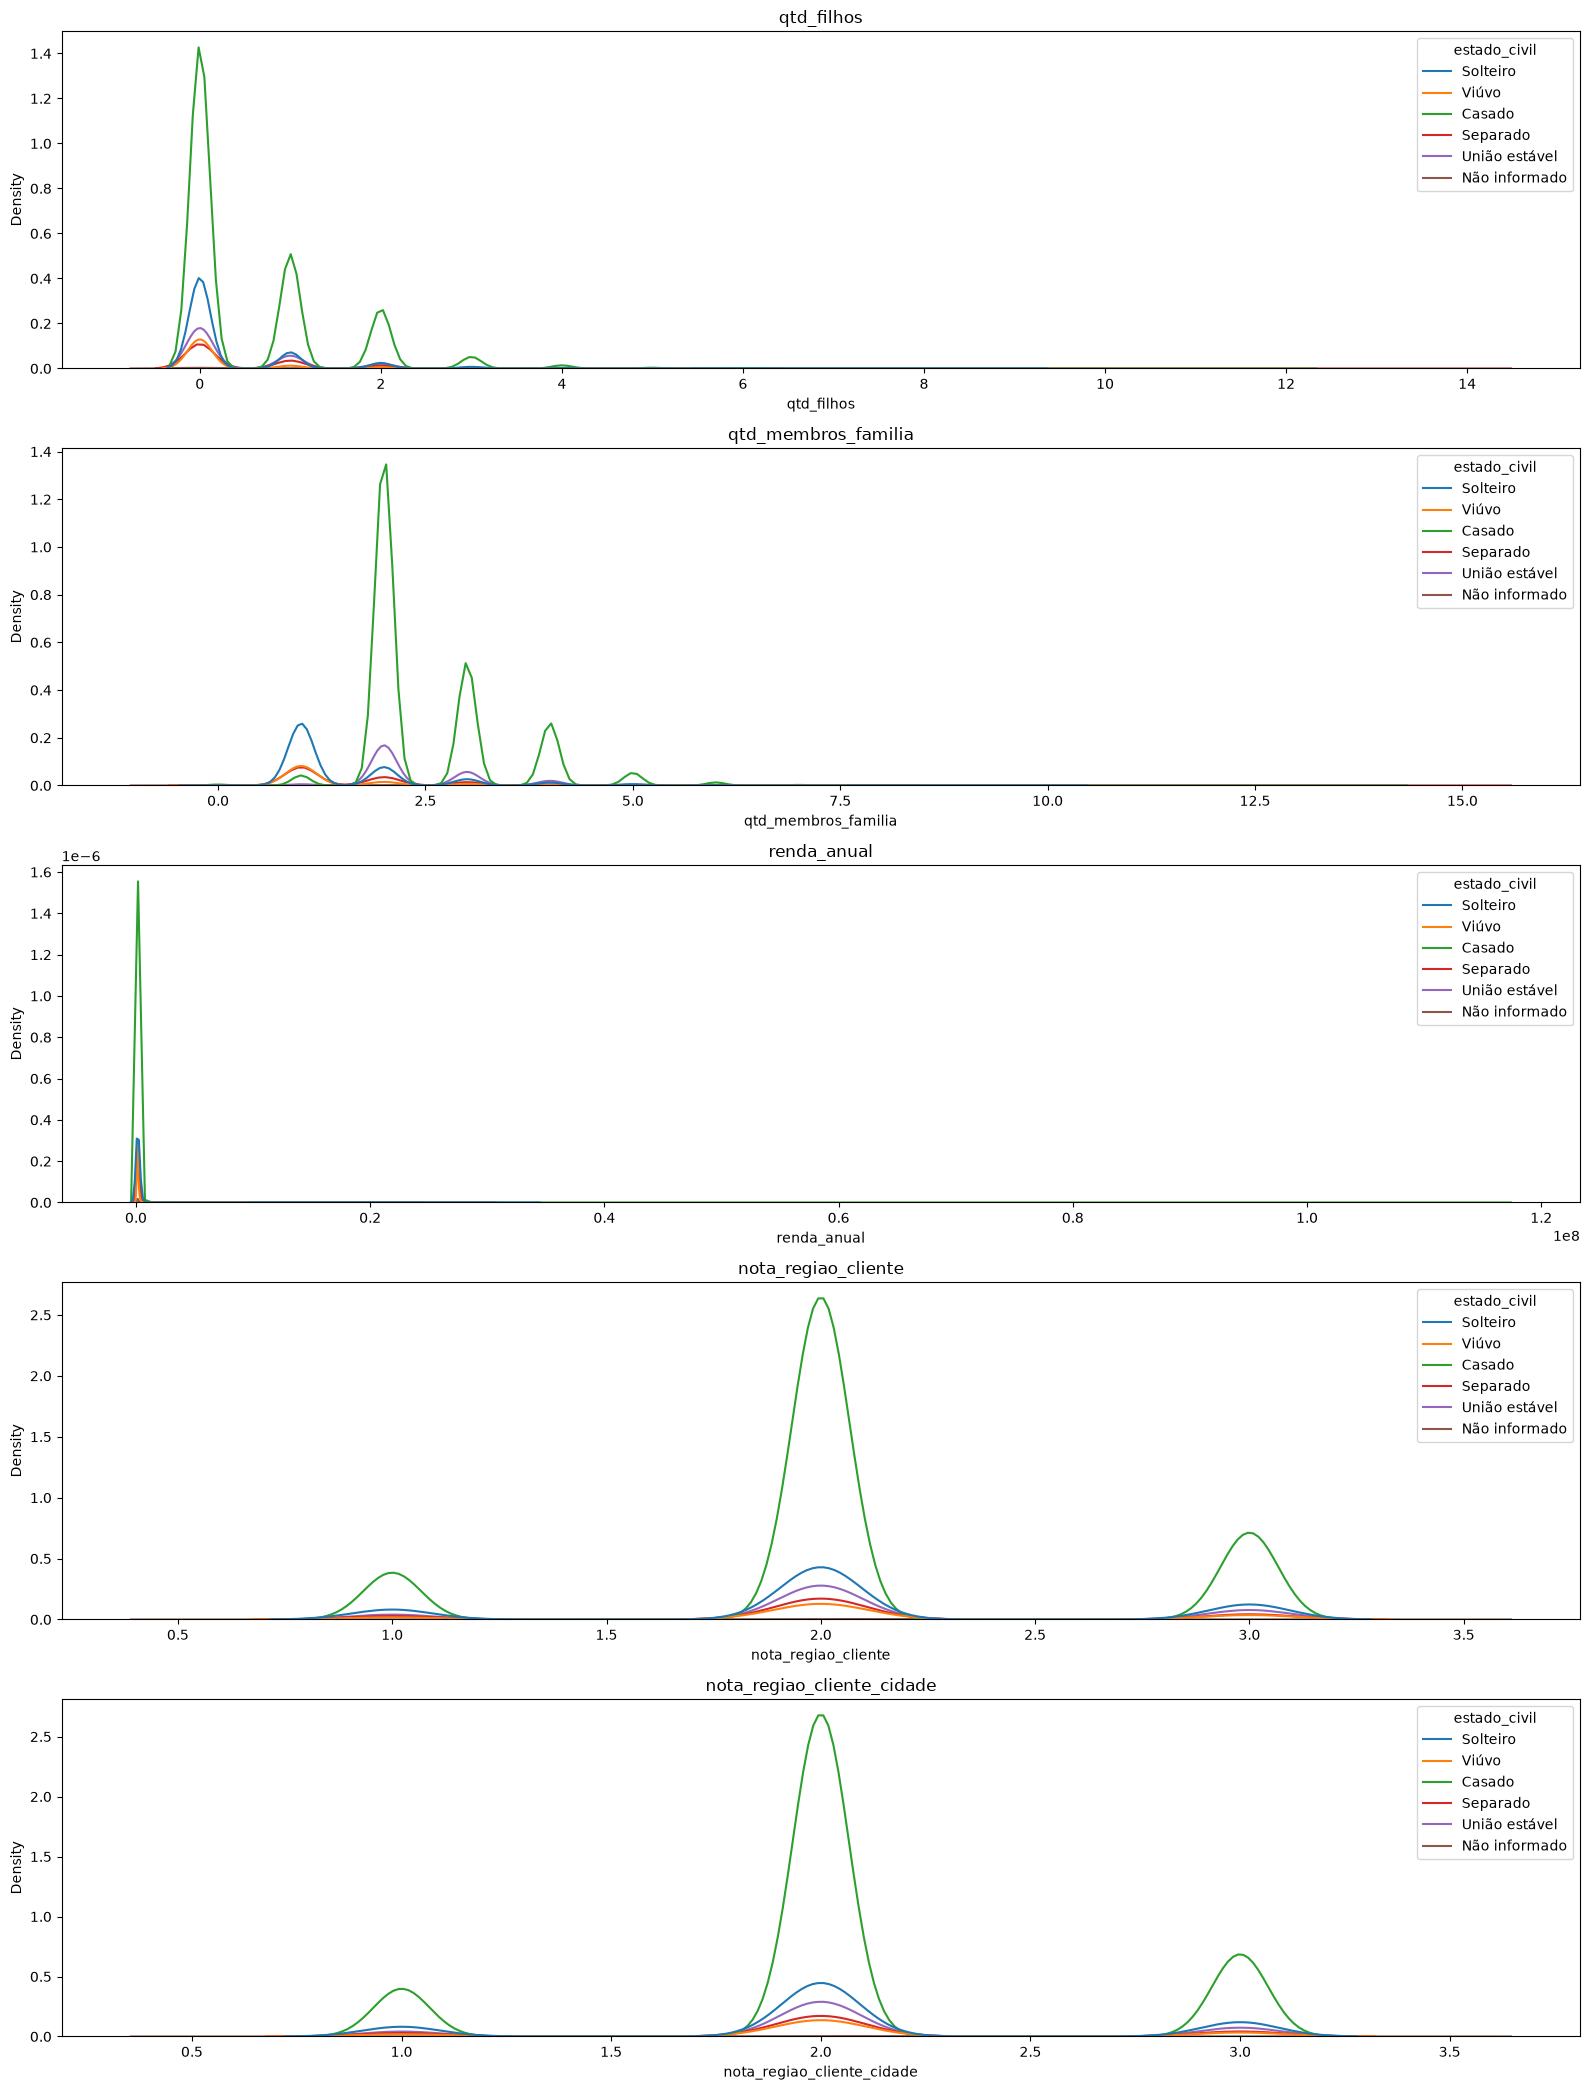

In [12]:
# verificando densidade de estado civil
kde_plot(df_cad, 'estado_civil')

- Vemos uma presença discrepante entre pessoas casadas com as demais estatisticas, como: renda anual, membros da famila e quantidade de filhos 


In [13]:
df_cad.groupby(['sexo', 'estado_civil'])['renda_anual'].agg(['mean', 'std', 'count']).sort_values('mean', ascending=False)

mean           std  count
sexo          estado_civil                                     
não informado União estável  281250.000000  2.652711e+05      4
masculino     Separado       225830.574108  1.071705e+06    796
              Casado         225647.956537  8.899678e+05  11832
              Solteiro       223885.827945  1.016112e+06   2818
              União estável  208402.136450  7.989752e+05   1555
feminino      Casado         195845.562341  1.206268e+06  19496
              Solteiro       190471.017941  8.274737e+05   4649
              Separado       185192.630107  5.996556e+05   2421
masculino     Não informado  175678.200000  9.168049e+04     54
não informado Separado       172500.000000  1.299038e+04      3
feminino      União estável  170966.751971  4.290225e+05   3292
masculino     Viúvo          168510.026572  9.383814e+04    318
feminino      Não informado  165651.664737  6.926105e+04     95
não informado Viúvo          160500.000000  6.595984e+04      6
              Casado         154360.714286  5.400596e+04     28
feminino      Viúvo          151543.374082  2.117193e+05   2212
não informado Solteiro       137700.000000  3.675459e+04     10

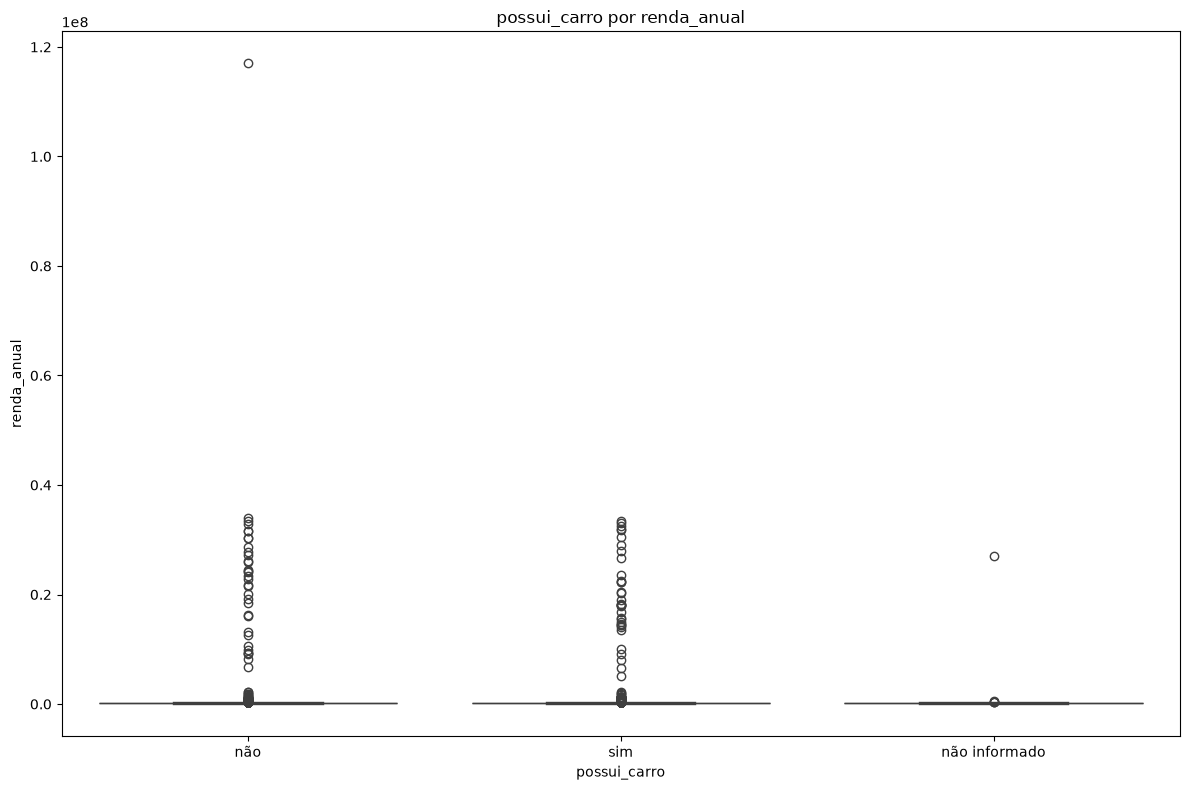

In [14]:
# renda anual e se o cliente possui carro
boxplot_hue(df_cad,'possui_carro', 'renda_anual')

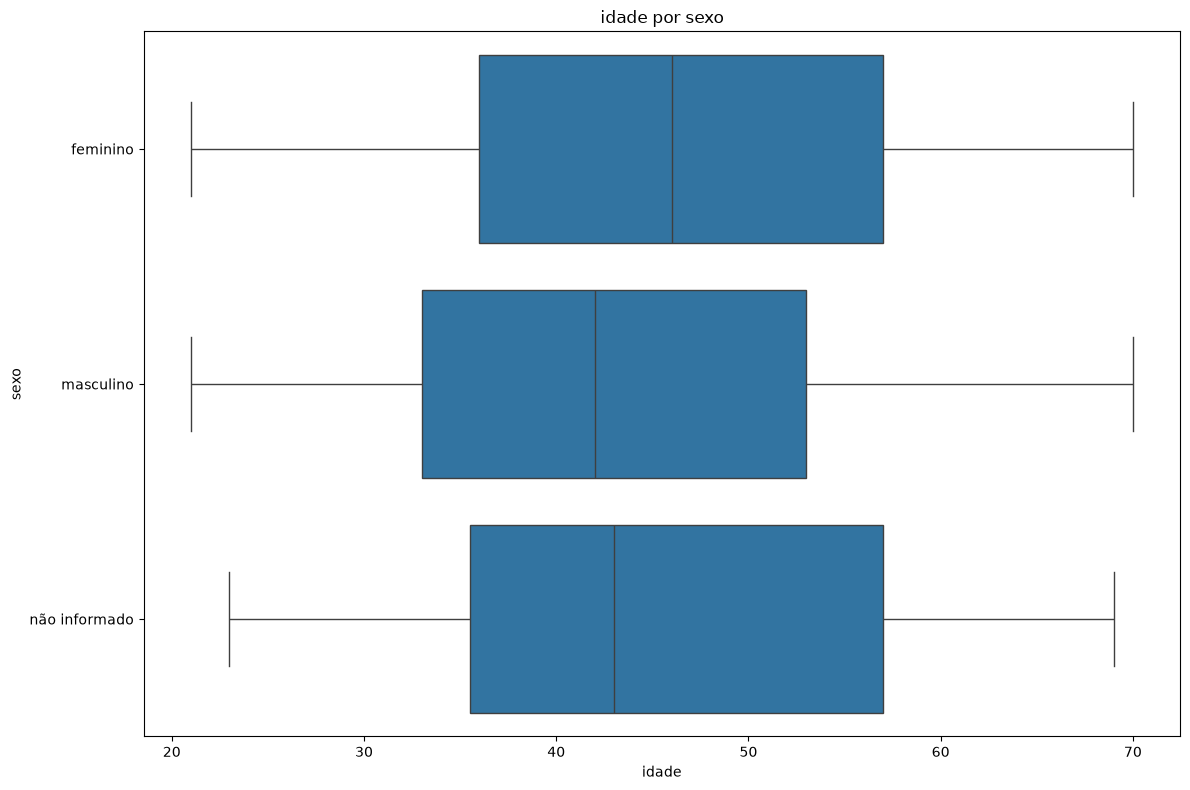

In [15]:
# idades por sexo 
boxplot_hue(df_cad, 'idade', 'sexo')

In [16]:
# idade média onde se possui ou nao um carro 
df_cad.groupby('possui_carro')['idade'].agg(['median', 'mean', 'std'])

,median,mean,std
possui_carro,,,
não,46.0,46.078678,12.672875
não informado,43.0,45.591837,12.916266
sim,42.0,43.350554,11.573938


In [17]:
# idade média para possuir ou nao um imovel
df_cad.groupby('possui_imovel')['idade'].agg(['median', 'mean', 'std'])

,median,mean,std
possui_imovel,,,
não,42.0,43.434369,12.212121
não informado,46.0,45.111111,12.599291
sim,46.0,45.897248,12.370118


In [18]:
# contagens de pessoas que possuem carro por nivel de educaçao
df_cad.groupby('nivel_educacao')['possui_carro'].agg('count')


nivel_educacao
Ensino fundamental              708
Ensino médio                  35047
Ensino superior               12039
Ensino superior incompleto     1722
Pós-graduação                    73
Name: possui_carro, dtype: int64

In [19]:
# pessoas que possuem imovel por nivel de educaçao e idade 
df_cad.groupby(['possui_imovel', 'nivel_educacao'])['idade'].agg(['mean', 'count', 'mean', 'std', 'min', 'max'])

mean  count       mean  \
possui_imovel nivel_educacao                                            
não           Ensino fundamental          45.563265    245  45.563265   
              Ensino médio                44.427125  10669  44.427125   
              Ensino superior             41.482899   3684  41.482899   
              Ensino superior incompleto  36.735974    606  36.735974   
              Pós-graduação               48.840000     25  48.840000   
não informado Ensino médio                46.138889     36  46.138889   
              Ensino superior             43.866667     15  43.866667   
              Ensino superior incompleto  37.000000      2  37.000000   
              Pós-graduação               43.000000      1  43.000000   
sim           Ensino fundamental          48.390929    463  48.390929   
              Ensino médio                46.862912  24342  46.862912   
              Ensino superior             44.013309   8340  44.013309   
              Ensino superior incompleto  37.953321   1114  37.953321   
              Pós-graduação               43.787234     47  43.787234   

                                                std   min   max  
possui_imovel nivel_educacao                                     
não           Ensino fundamental          13.603921  21.0  69.0  
              Ensino médio                12.207195  21.0  70.0  
              Ensino superior             11.613234  21.0  70.0  
              Ensino superior incompleto  11.698256  21.0  69.0  
              Pós-graduação               11.367644  27.0  69.0  
não informado Ensino médio                12.583783  22.0  65.0  
              Ensino superior             13.484736  25.0  67.0  
              Ensino superior incompleto  11.313708  29.0  45.0  
              Pós-graduação                     NaN  43.0  43.0  
sim           Ensino fundamental          13.613897  22.0  70.0  
              Ensino médio                12.271606  21.0  70.0  
              Ensino superior             12.013890  21.0  70.0  
              Ensino superior incompleto  12.015697  22.0  69.0  
              Pós-graduação               13.330149  22.0  69.0

# Tabela emprestimos

In [20]:
df_emp = LoadSQLTable().load_emprestimos()
df_emp = df_emp.set_index(['id_cliente', 'id_contrato'])

In [21]:
df_emp.head()

,,tipo_contrato,status_contrato,data_decisao,valor_solicitado,valor_credito,valor_bem,valor_parcela,qtd_parcelas_planejadas,tipo_pagamento,finalidade_emprestimo,...,setor_vendedor,canal_venda,area_venda,dia_semana_solicitacao,hora_solicitacao,indicador_ultima_solicitacao_contrato,indicador_ultima_solicitacao_dia,motivo_recusa,valor_bem_ausente,valor_parcela_ausente
id_cliente,id_contrato,,,,,,,,,,,,,,,,,,,,,
262196,2474552,financiamento de consumo,Aprovado,2017-02-04 00:00:00,15160.5,13644.0,15160.5,2163.960,8.0,Dinheiro pelo banco,Não se aplica,...,Conectividade,Rede nacional,20,sábado,17:13:02,Sim,1,Não se aplica,0,0
436388,1100313,financiamento de consumo,Aprovado,2017-02-06 00:00:00,0.0,112500.0,115110.0,5625.000,0.0,Não informado,Não se aplica,...,Não informado,Central de atendimento,-1,segunda-feira,15:39:39,Sim,1,Não se aplica,1,0
265591,1810185,financiamento de consumo,Recusado,2017-02-07 00:00:00,34106.4,36355.5,34106.4,5765.985,8.0,Dinheiro pelo banco,Não se aplica,...,Eletrônicos de consumo,Rede nacional,934,terça-feira,19:57:50,Sim,1,Verificação cadastral,0,0
237225,2253903,Empréstimo em dinheiro,Aprovado,2017-02-07 00:00:00,26518.5,24606.0,26518.5,4938.435,6.0,Dinheiro pelo banco,Não se aplica,...,Conectividade,Rede nacional,33,terça-feira,15:49:37,Sim,1,Não se aplica,0,0
318283,2617515,Crédito rotativo,Aprovado,2017-02-07 00:00:00,14539.5,15259.5,14539.5,3062.565,6.0,Dinheiro pelo banco,Não se aplica,...,Conectividade,Rede nacional,90,terça-feira,09:48:47,Sim,1,Não se aplica,0,0


In [22]:
# separando tipos das colunas 
num_col_emp = df_emp.select_dtypes(include='number')
cat_col_emp = df_emp.select_dtypes(exclude='number').columns

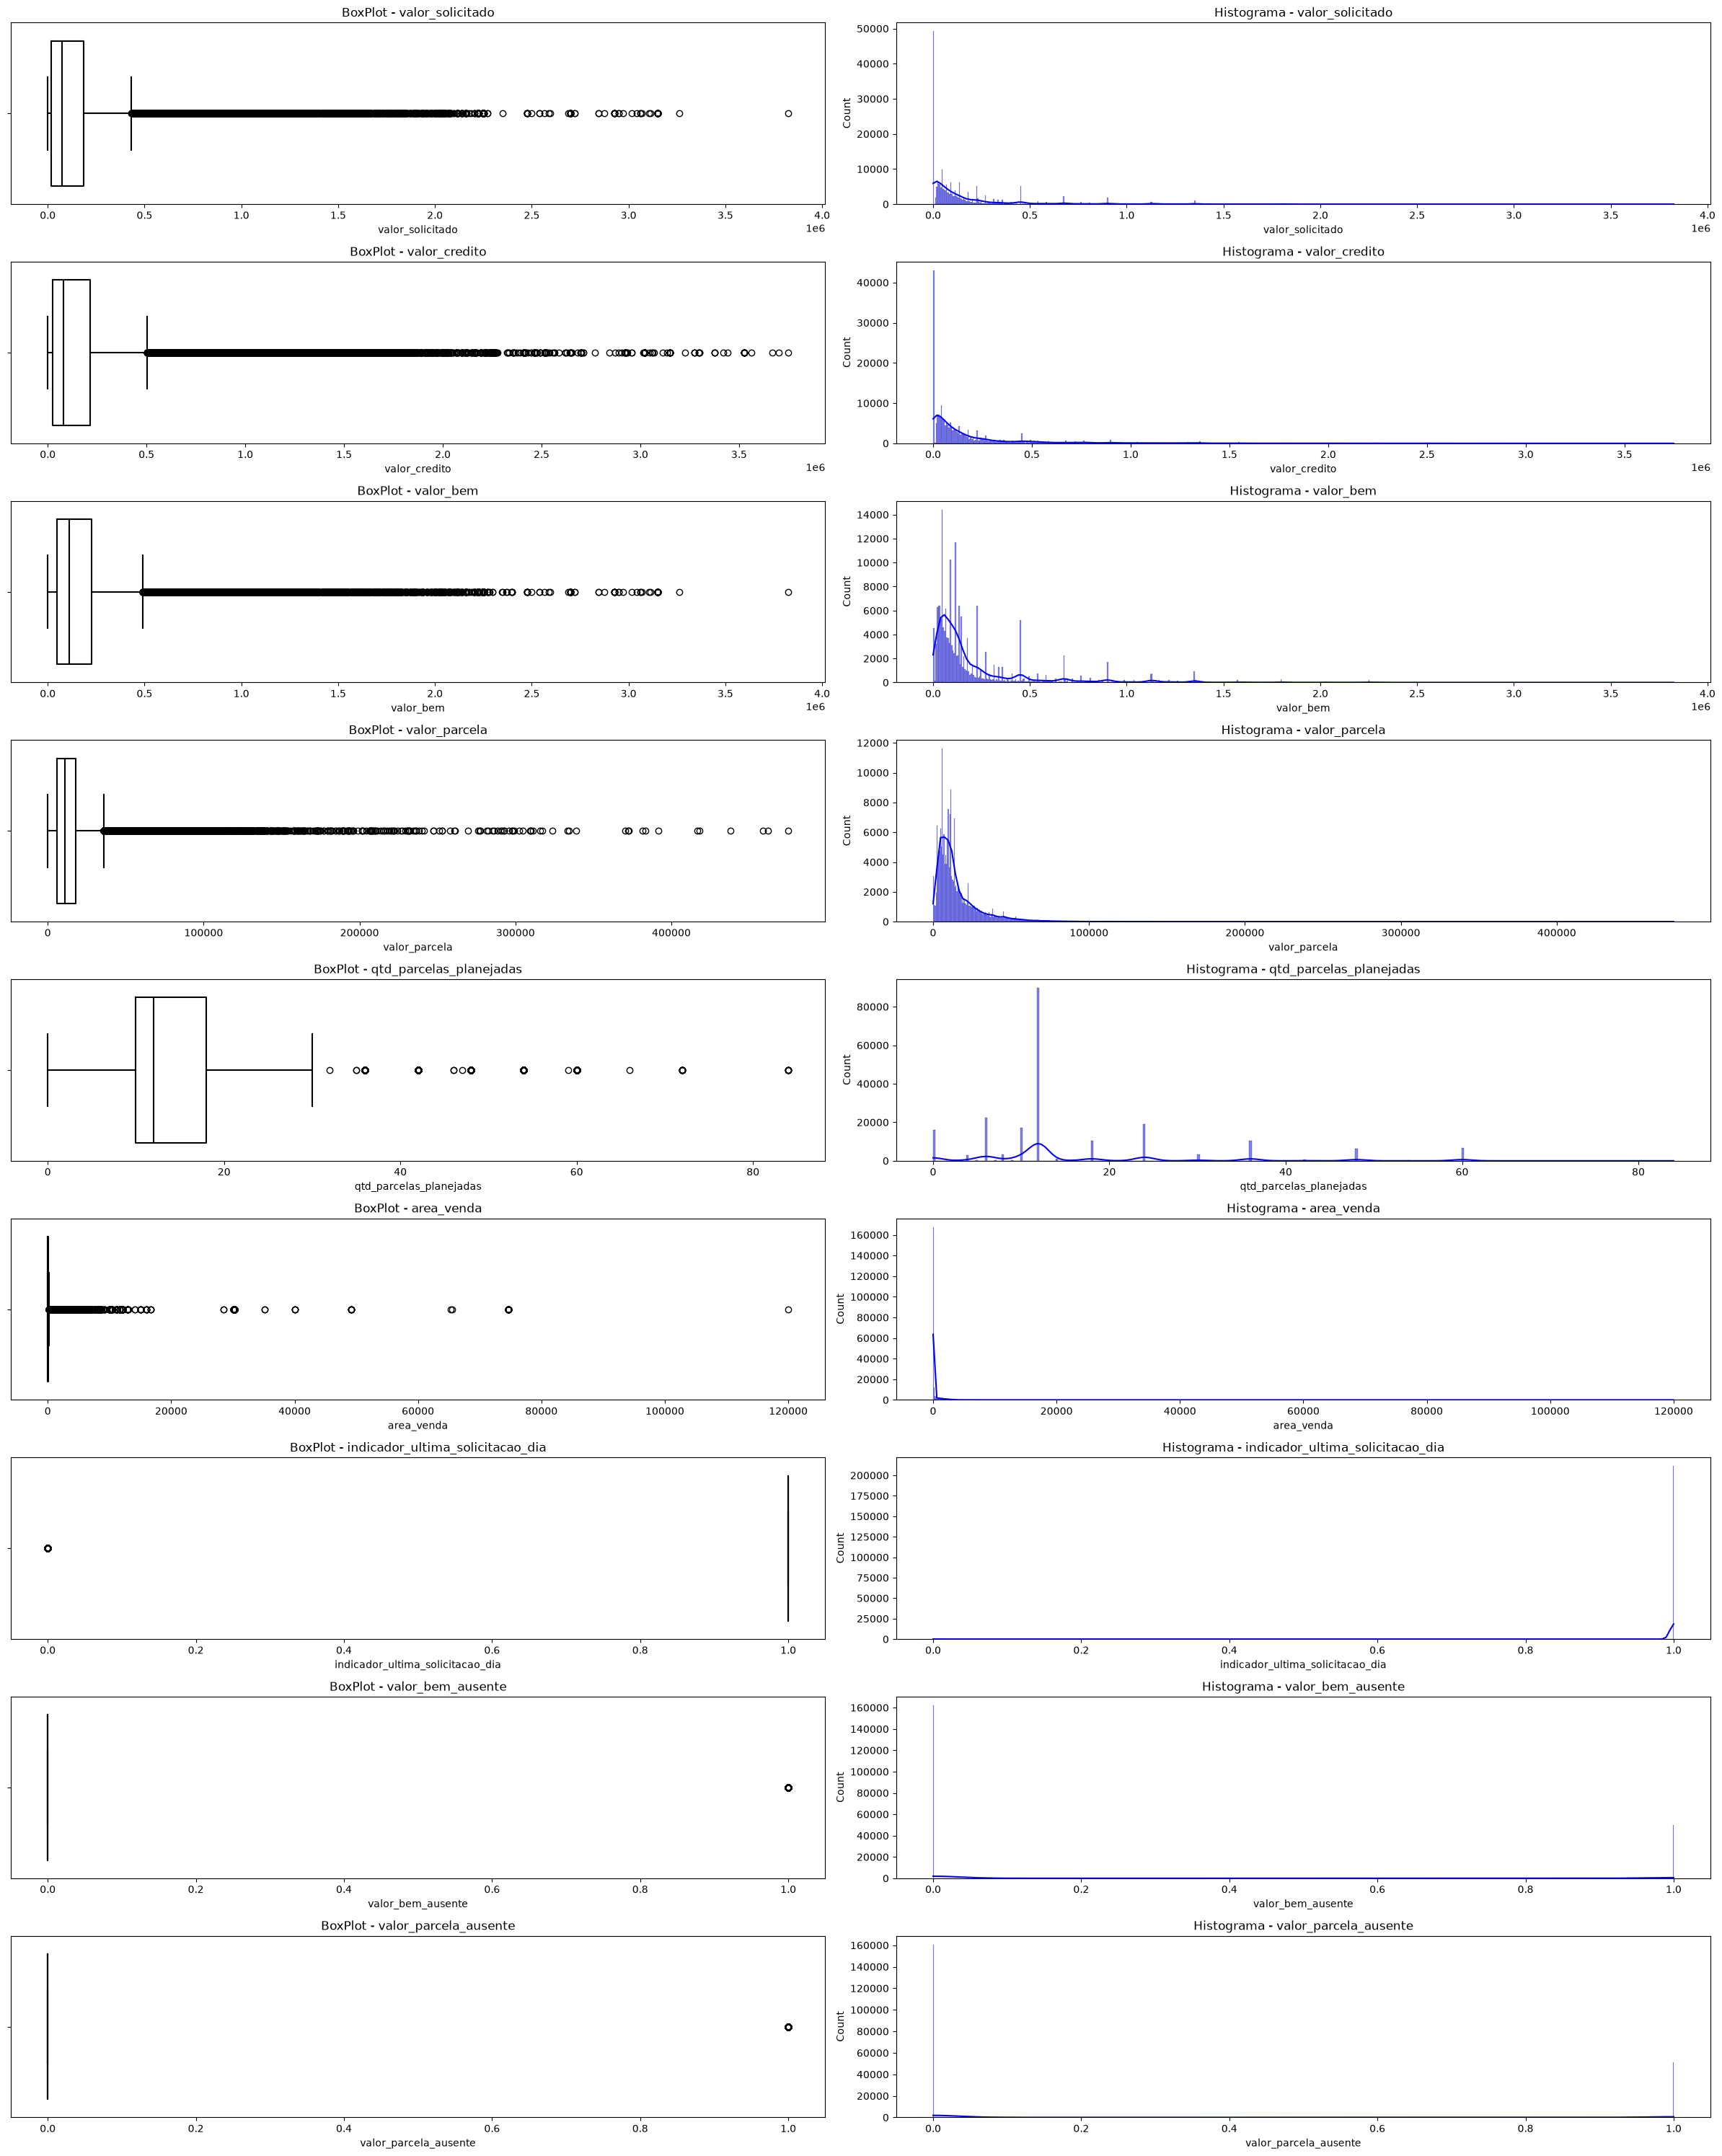

In [23]:
# plotando colunas numericas de emprestimo 
PlotDistribution().num_plot(df_emp, list(num_col_emp.columns))

In [24]:
df_emp.info()

<class 'pandas.DataFrame'>
MultiIndex: 211917 entries, (np.int64(262196), np.int64(2474552)) to (np.int64(113098), np.int64(1131374))
Data columns (total 26 columns):
 #   Column                                 Non-Null Count   Dtype  
---  ------                                 --------------   -----  
 0   tipo_contrato                          211917 non-null  str    
 1   status_contrato                        211917 non-null  str    
 2   data_decisao                           211917 non-null  str    
 3   valor_solicitado                       211917 non-null  float64
 4   valor_credito                          211917 non-null  float64
 5   valor_bem                              181773 non-null  float64
 6   valor_parcela                          182745 non-null  float64
 7   qtd_parcelas_planejadas                211917 non-null  float64
 8   tipo_pagamento                         211917 non-null  str    
 9   finalidade_emprestimo                  211917 non-null  str    
 10  

In [25]:
# tratando colunas de data e hora
df_emp['hora_solicitacao'] = pd.to_datetime(df_emp['hora_solicitacao'], format='%H:%M:%S', errors='coerce').dt.hour
df_emp['data_decisao'] = pd.to_datetime(df_emp['data_decisao'], errors='coerce').dt.normalize()

In [26]:
# verificando proporçao da hora de solicitaçao
df_emp['hora_solicitacao'].value_counts(normalize=True)

hora_solicitacao
11    0.115116
12    0.111454
10    0.109817
13    0.103710
14    0.094027
15    0.084472
9     0.076403
16    0.072344
17    0.058598
8     0.043626
18    0.038072
7     0.027487
19    0.019593
6     0.015298
5     0.008749
20    0.008664
4     0.005573
3     0.003209
21    0.002326
2     0.000680
22    0.000368
23    0.000165
1     0.000137
0     0.000113
Name: proportion, dtype: float64

In [27]:
# criando faixas do dia 
df_emp['faixa_do_dia'] = pd.cut(df_emp['hora_solicitacao'], bins=[-1, 5, 12,17, 23], labels=['madrugada', 'manhã', 'tarde', 'noite'])
df_emp.head()

,,tipo_contrato,status_contrato,data_decisao,valor_solicitado,valor_credito,valor_bem,valor_parcela,qtd_parcelas_planejadas,tipo_pagamento,finalidade_emprestimo,...,canal_venda,area_venda,dia_semana_solicitacao,hora_solicitacao,indicador_ultima_solicitacao_contrato,indicador_ultima_solicitacao_dia,motivo_recusa,valor_bem_ausente,valor_parcela_ausente,faixa_do_dia
id_cliente,id_contrato,,,,,,,,,,,,,,,,,,,,,
262196,2474552,financiamento de consumo,Aprovado,2017-02-04,15160.5,13644.0,15160.5,2163.960,8.0,Dinheiro pelo banco,Não se aplica,...,Rede nacional,20,sábado,17,Sim,1,Não se aplica,0,0,tarde
436388,1100313,financiamento de consumo,Aprovado,2017-02-06,0.0,112500.0,115110.0,5625.000,0.0,Não informado,Não se aplica,...,Central de atendimento,-1,segunda-feira,15,Sim,1,Não se aplica,1,0,tarde
265591,1810185,financiamento de consumo,Recusado,2017-02-07,34106.4,36355.5,34106.4,5765.985,8.0,Dinheiro pelo banco,Não se aplica,...,Rede nacional,934,terça-feira,19,Sim,1,Verificação cadastral,0,0,noite
237225,2253903,Empréstimo em dinheiro,Aprovado,2017-02-07,26518.5,24606.0,26518.5,4938.435,6.0,Dinheiro pelo banco,Não se aplica,...,Rede nacional,33,terça-feira,15,Sim,1,Não se aplica,0,0,tarde
318283,2617515,Crédito rotativo,Aprovado,2017-02-07,14539.5,15259.5,14539.5,3062.565,6.0,Dinheiro pelo banco,Não se aplica,...,Rede nacional,90,terça-feira,9,Sim,1,Não se aplica,0,0,manhã


In [28]:
# verificando frequencias das colunas categoricas
for cat in cat_col_emp:
    print(f'proporçao coluna: {cat}')
    print(df_emp[cat].value_counts(normalize=True))
    print('---'*50)
    print()
print(df_emp['faixa_do_dia'].value_counts(normalize=(True)))

proporçao coluna: tipo_contrato
tipo_contrato
Empréstimo em dinheiro      0.379809
financiamento de consumo    0.369857
Crédito rotativo            0.250334
Name: proportion, dtype: float64
------------------------------------------------------------------------------------------------------------------------------------------------------

proporçao coluna: status_contrato
status_contrato
Aprovado                0.621630
Cancelado               0.189909
Recusado                0.171548
Oferta não utilizada    0.016912
Name: proportion, dtype: float64
------------------------------------------------------------------------------------------------------------------------------------------------------

proporçao coluna: data_decisao
data_decisao
2024-06-26    0.001458
2024-05-27    0.001444
2024-06-04    0.001420
2024-08-21    0.001416
2024-07-19    0.001387
                ...   
2025-03-06    0.000019
2025-03-09    0.000014
2017-02-04    0.000005
2017-02-06    0.000005
2025-03-08    0.0

- O motivo de recusa que mais é frequente é a "nao se aplica"
- a faixa do dia que mais é solicidado emprestimo é a manhã, seguido com a parte da tarde
- o canal de venda que mais cede emprestimo são as Agências de crédito e dinheiro 
- a categoria de bem mais frequente é o "Não informado", o mesmo padrão se aplica ao tipo de produto 
- o tipo de cliente mais frequente é o "Recorrente"
- o tipo de pagamento mais frequente é o "Dinheiro pelo banco"
- 62% dos emprestimos foram aprovados


In [29]:
# tipos de contrato e valor solicitado 
df_emp.groupby('tipo_contrato')['valor_solicitado'].agg(['mean', 'std'])

,mean,std
tipo_contrato,,
Crédito rotativo,173677.163258,289137.137714
Empréstimo em dinheiro,178437.278630,293703.634512
financiamento de consumo,176155.796395,293513.895458


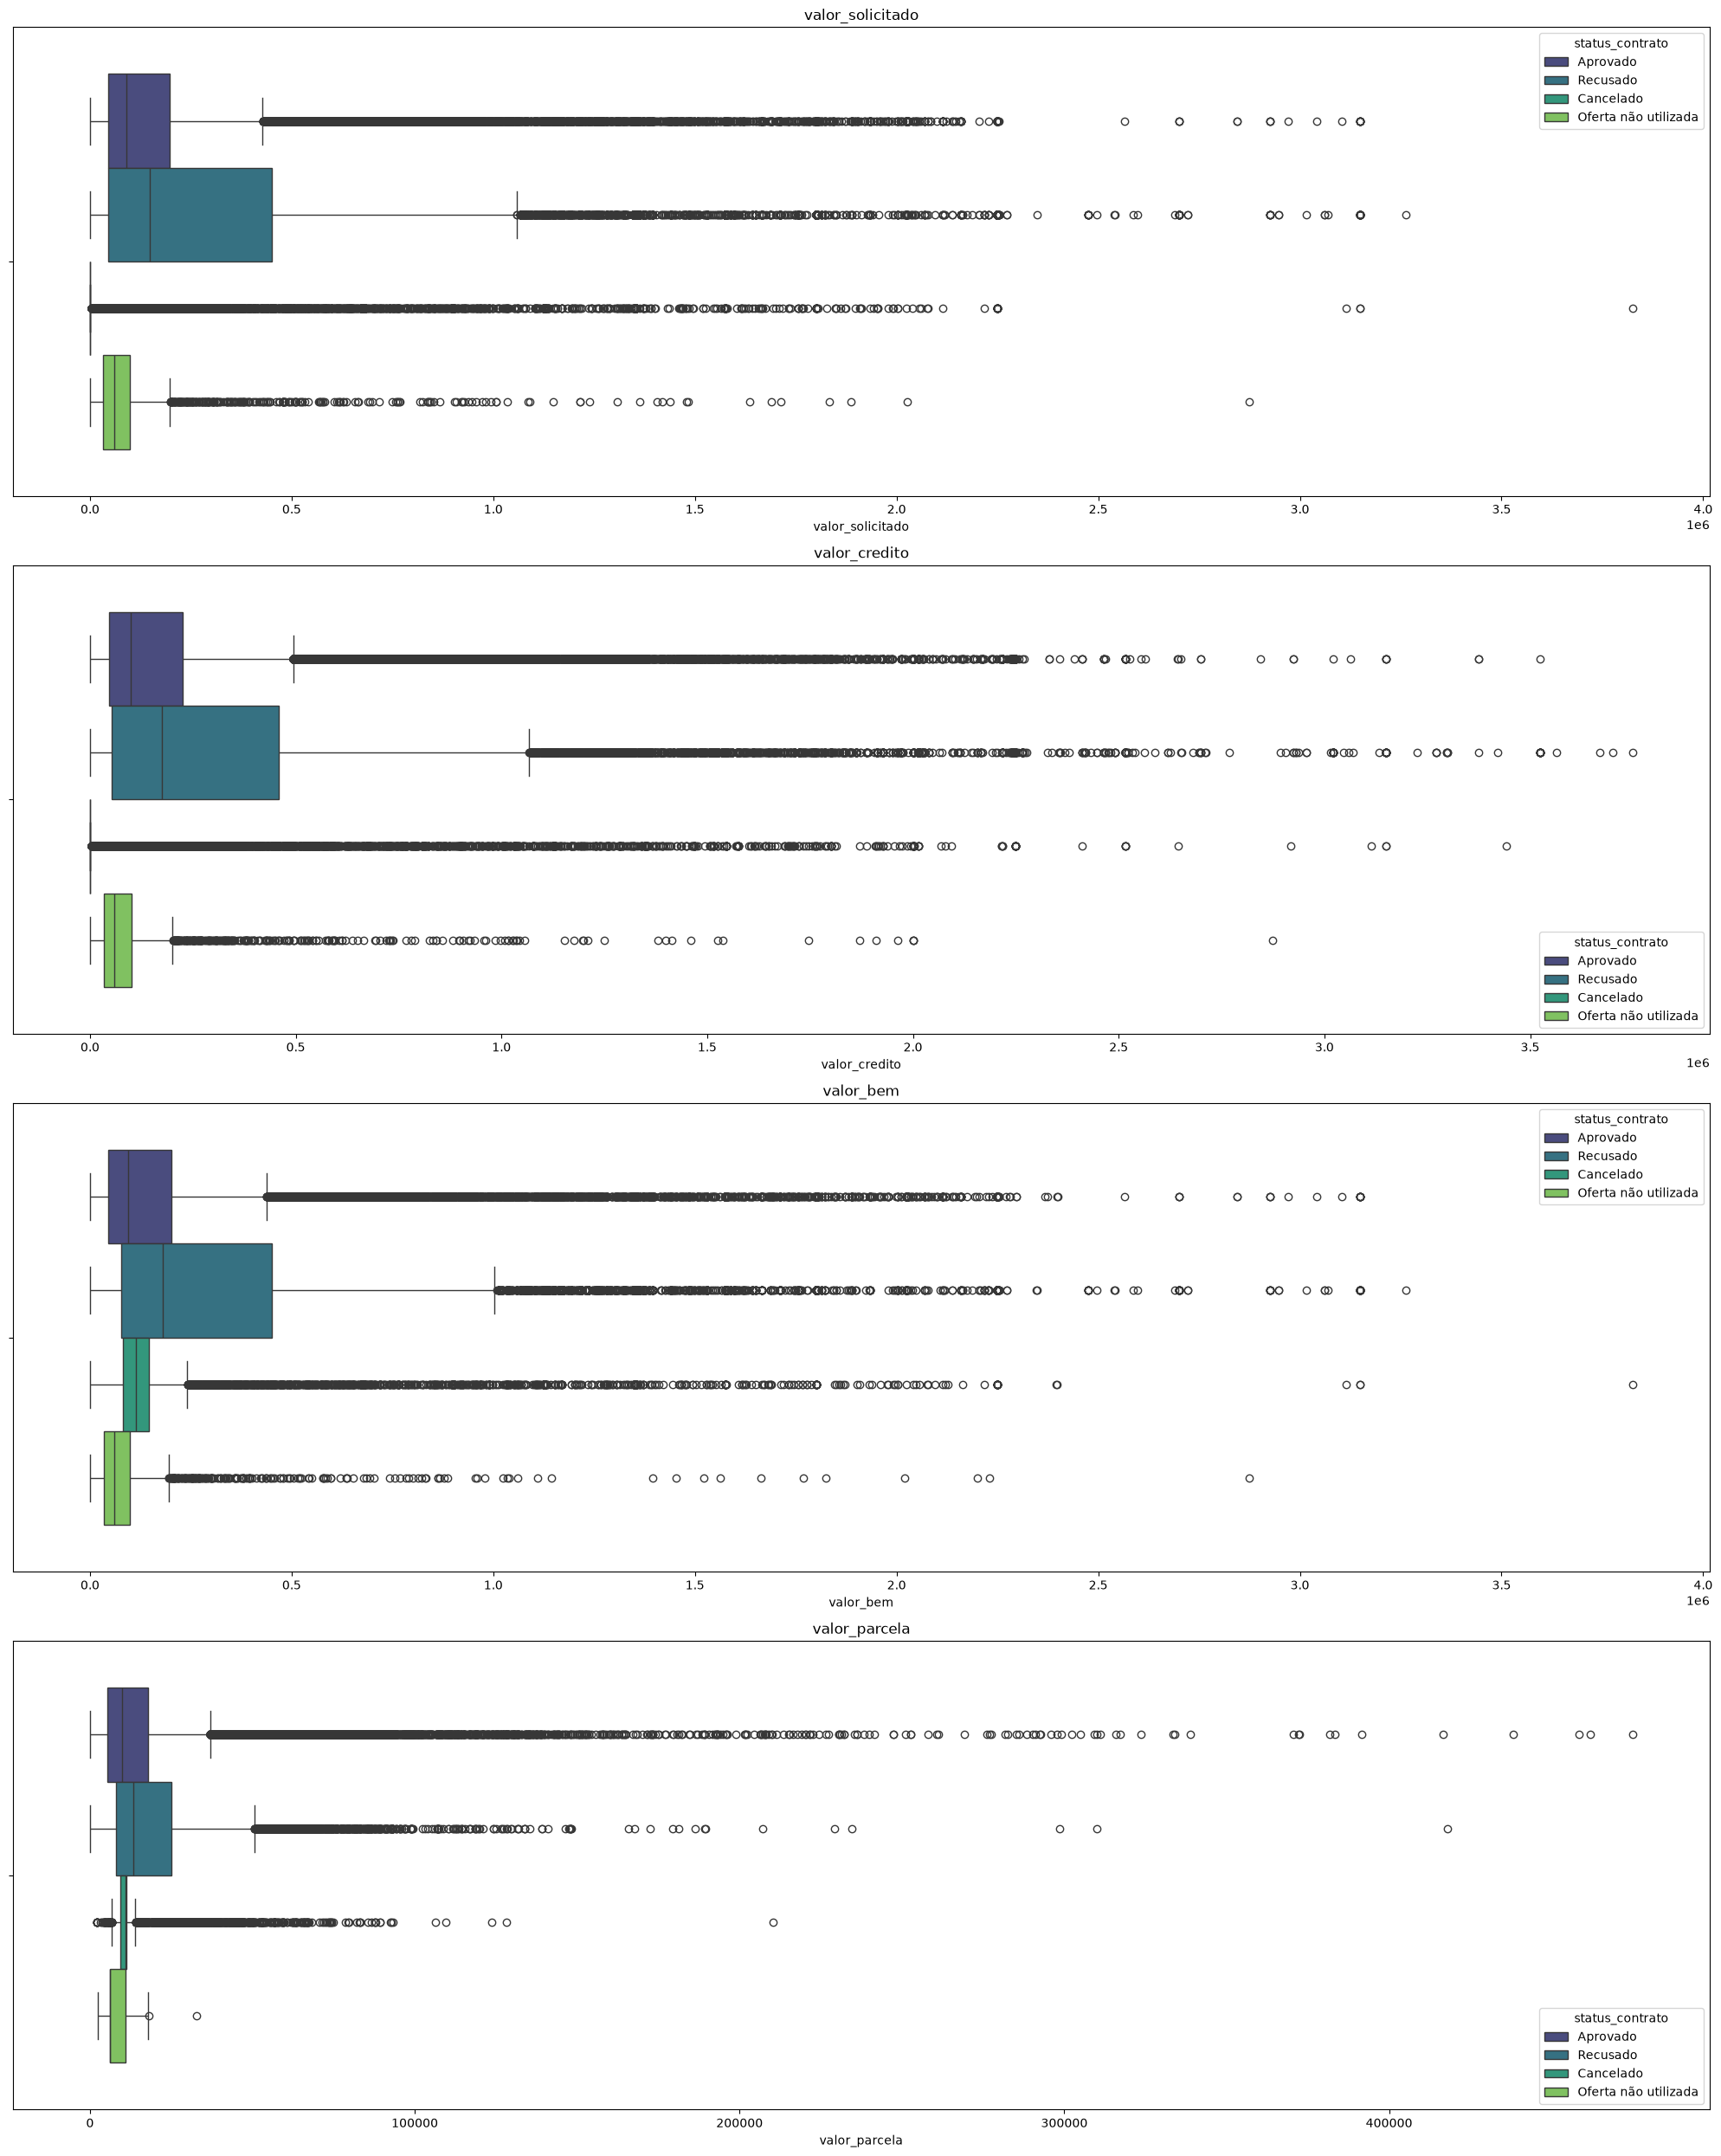

In [30]:
# verificando valores por status do contrato
hue_num_cols = ['valor_solicitado', 'valor_credito', 'valor_bem', 'valor_parcela']
fig, axes = plt.subplots(nrows=len(hue_num_cols), figsize=(20,25))
for ax, num in zip(axes, hue_num_cols):
    sns.boxplot(data=df_emp, x=f'{num}', hue='status_contrato', ax=ax, palette='viridis')
    ax.set_title(f'{num}')
fig.tight_layout()
fig.show()

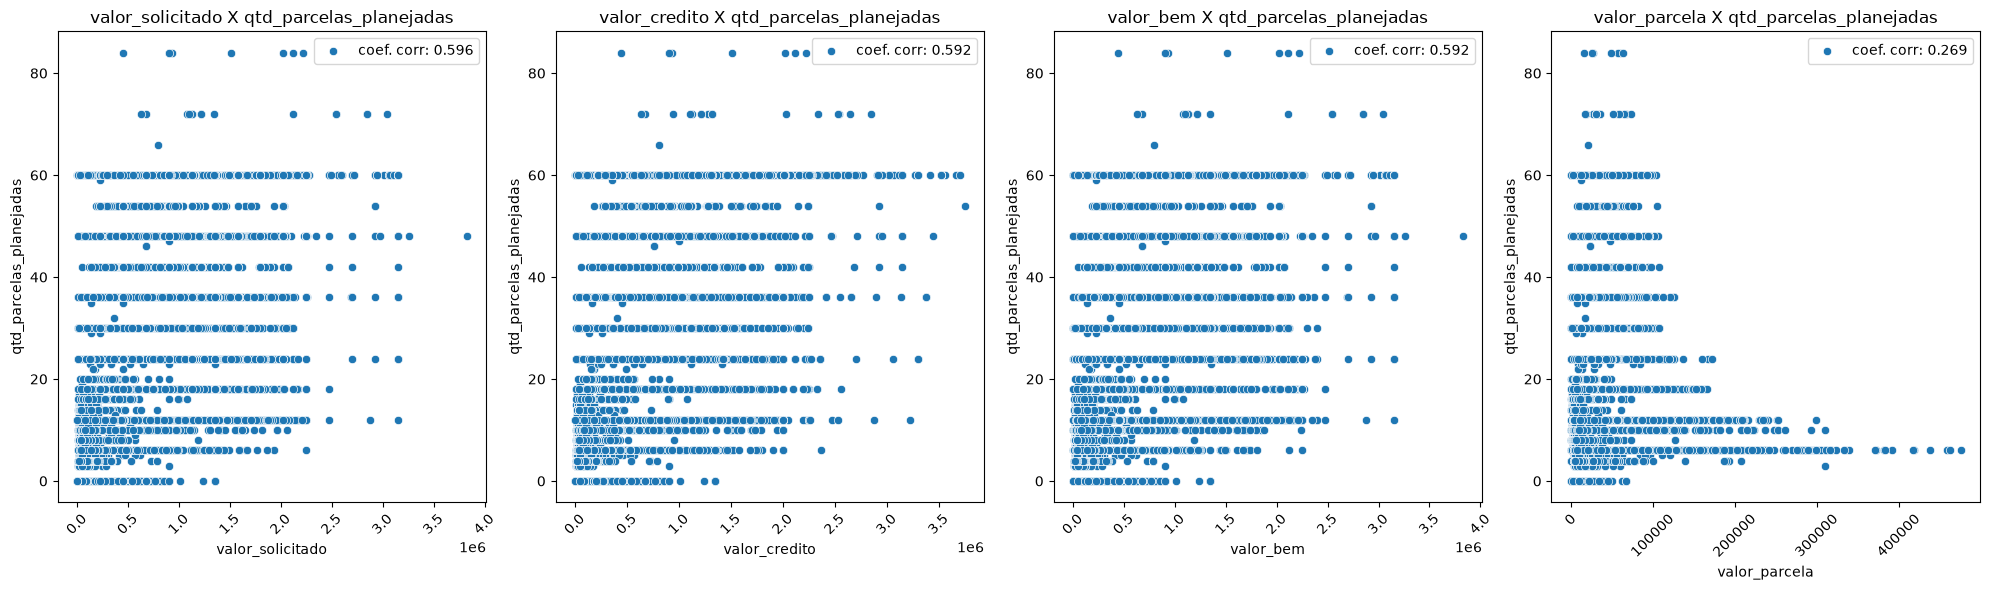

In [31]:
# correlaçao entre valores e quantidade de parcelas 
fig, axes = plt.subplots(ncols=len(hue_num_cols), nrows=1, figsize=(5 *len(hue_num_cols),6))
for ax, num in zip(axes, hue_num_cols):
    sns.scatterplot(data=df_emp, x=f'{num}', y='qtd_parcelas_planejadas', ax=ax, label=f"coef. corr: {round(df_emp[num].corr(df_emp['qtd_parcelas_planejadas']),3)}")
    ax.set_title(f'{num} X qtd_parcelas_planejadas')
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

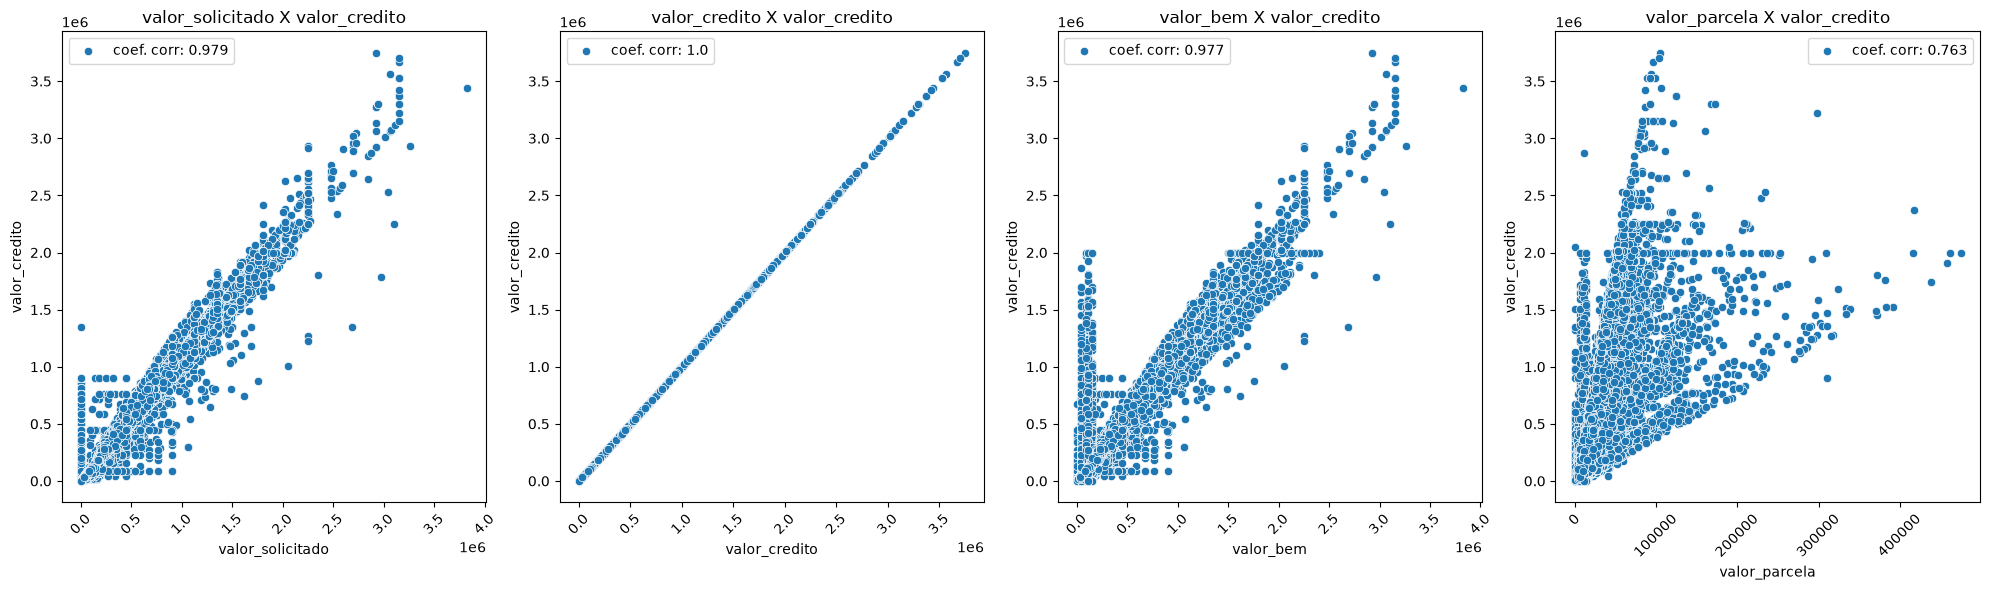

In [32]:
# relaçao linear entre valores e valor_credito
fig, axes = plt.subplots(ncols=len(hue_num_cols), nrows=1, figsize=(5 *len(hue_num_cols),6))
for i, (ax, num) in enumerate(zip(axes, hue_num_cols)):
    sns.scatterplot(data=df_emp, x=f'{num}', y=f'valor_credito', ax=ax, label=f"coef. corr: {round(df_emp[num].corr(df_emp['valor_credito']),3)}")
    ax.set_title(f'{num} X valor_credito')
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

valor_solicitado
desvio padrao: 59802.19386258814
mediana: 174832.8734674512

valor_credito
desvio padrao: 57473.73890425576
mediana: 184323.99550105684

valor_bem
desvio padrao: 32595.105202971983
mediana: 183604.7500566383

valor_parcela
desvio padrao: 2018.864087190483
mediana: 13152.775531242933



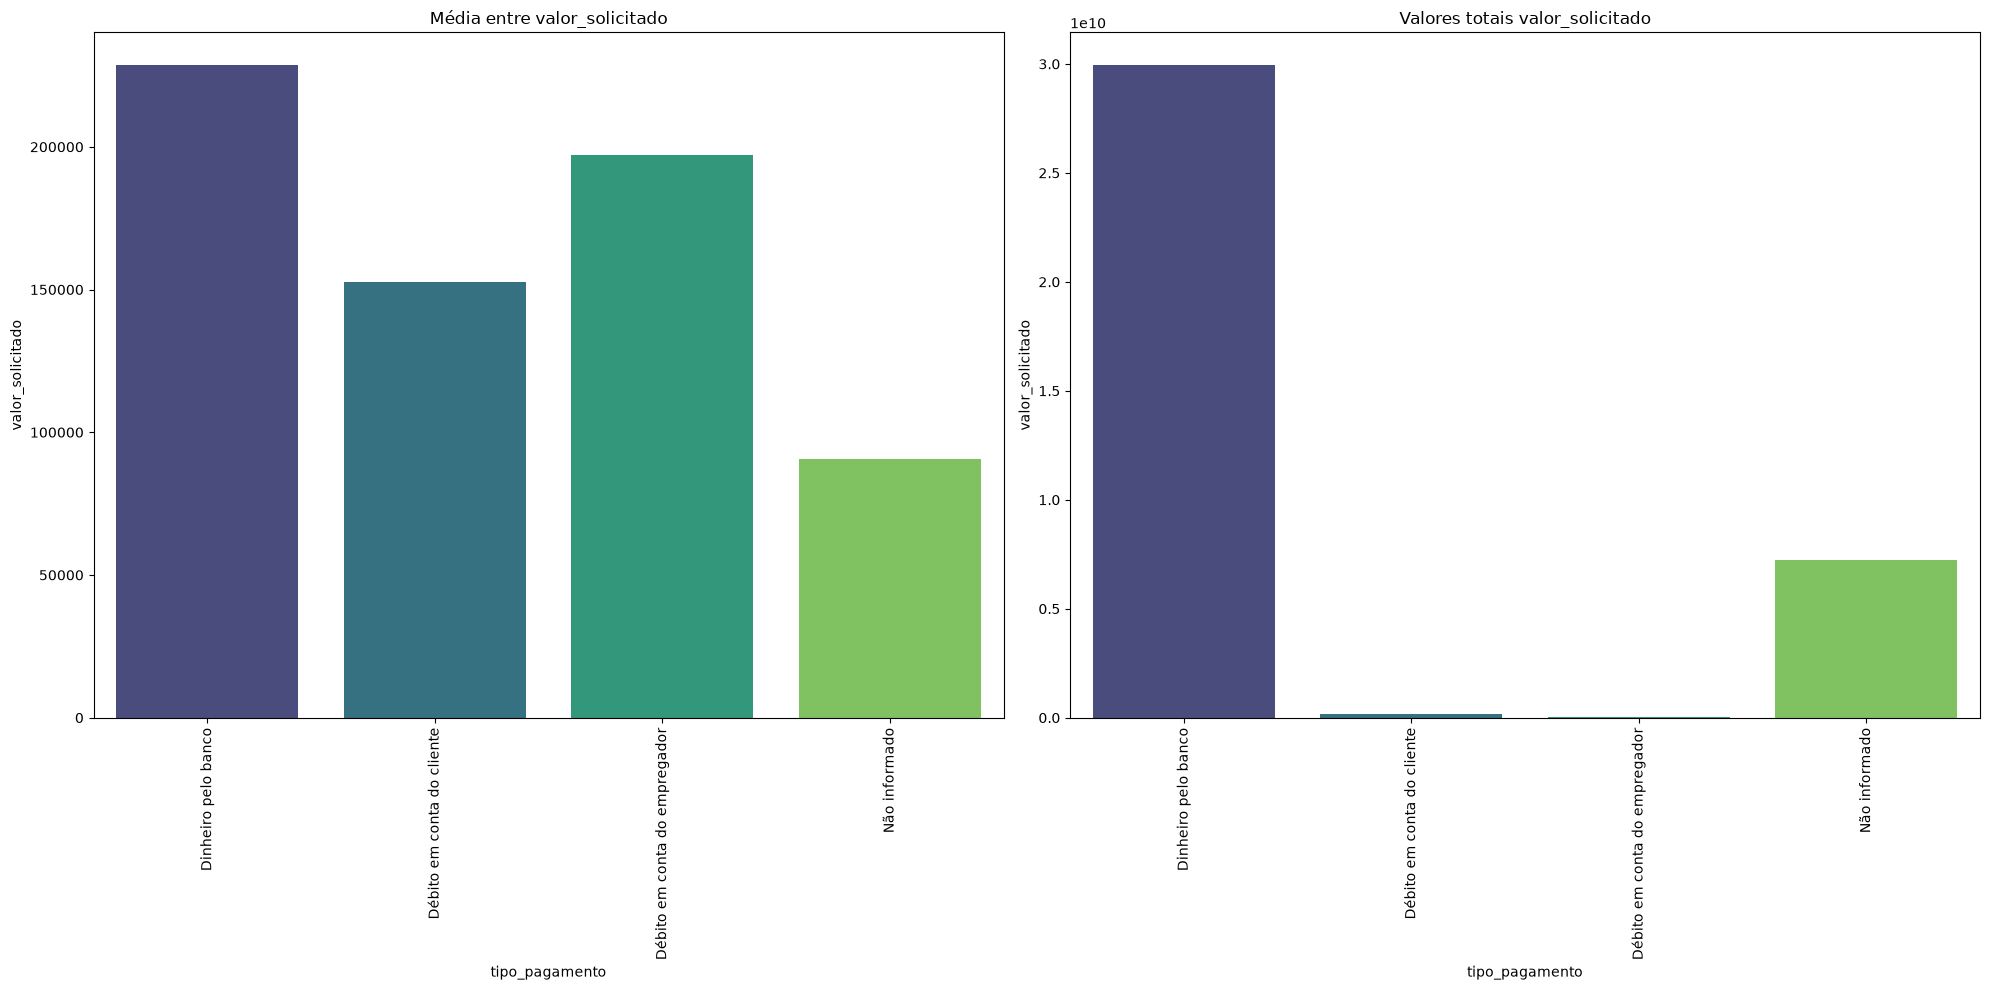

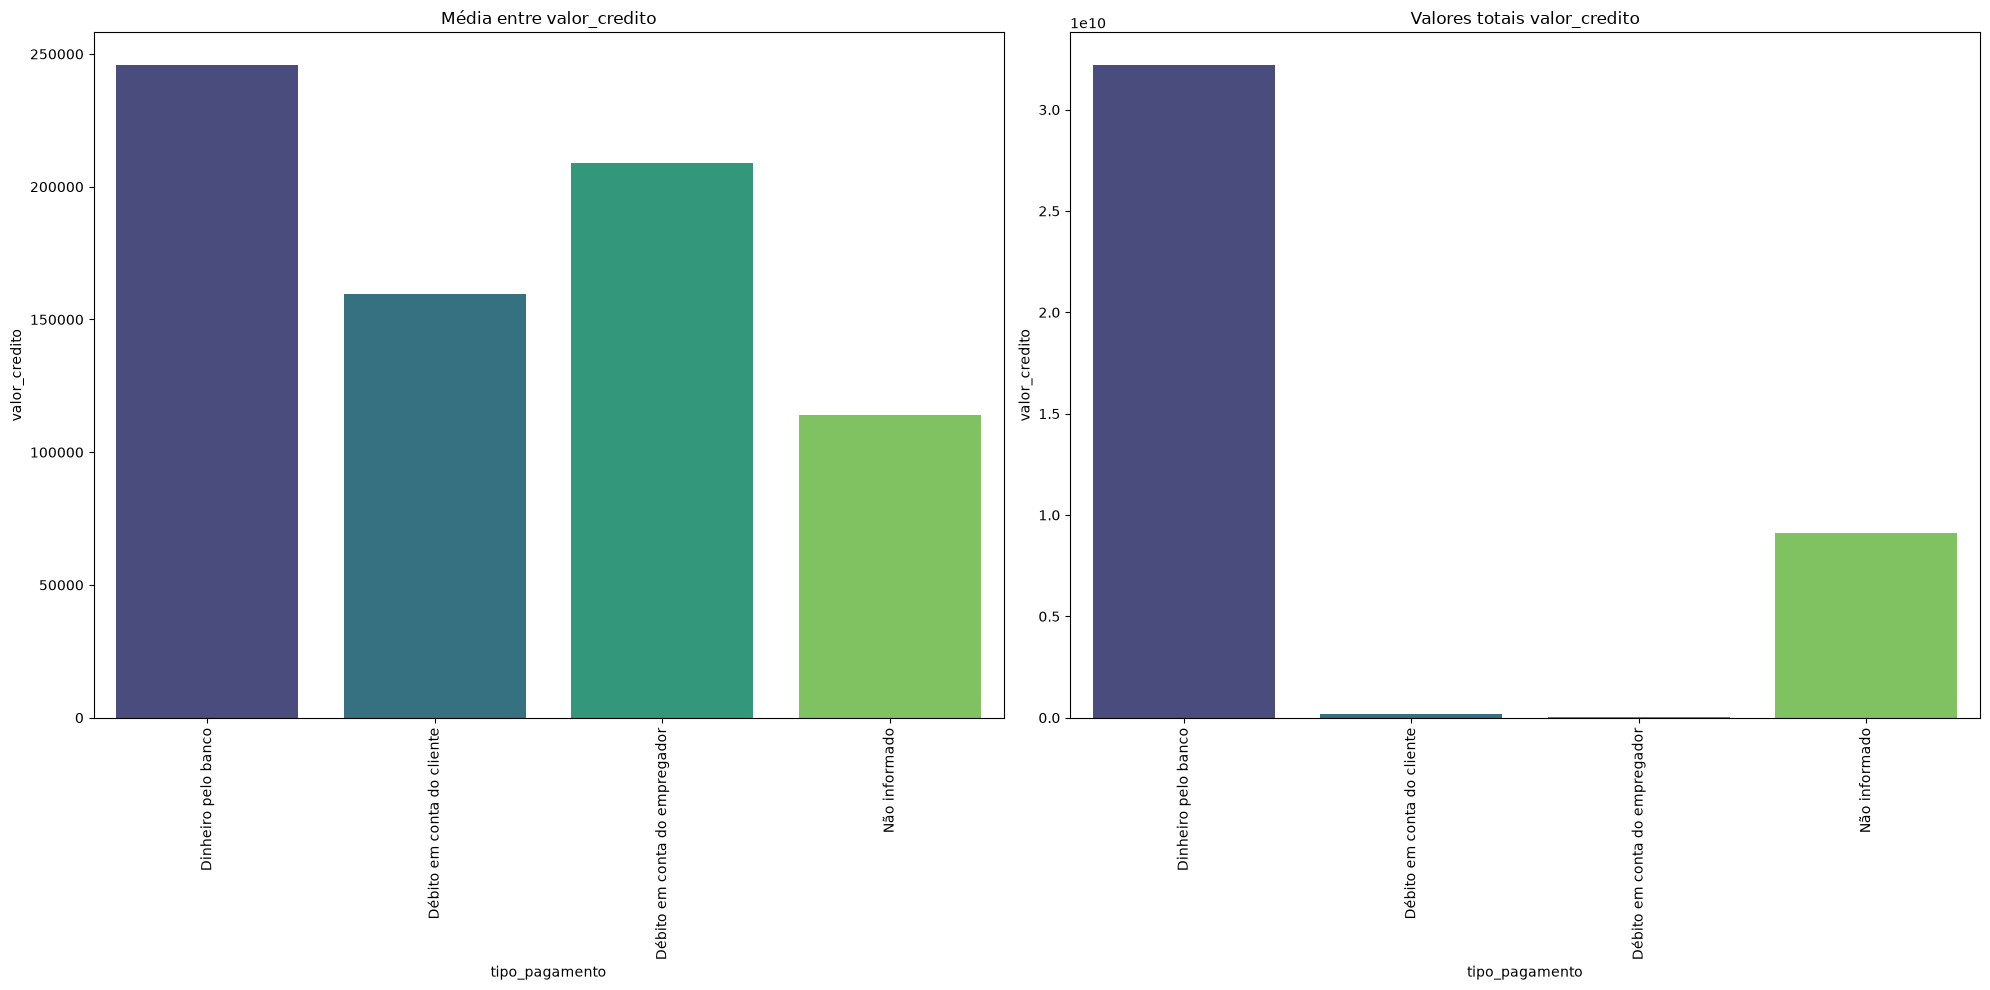

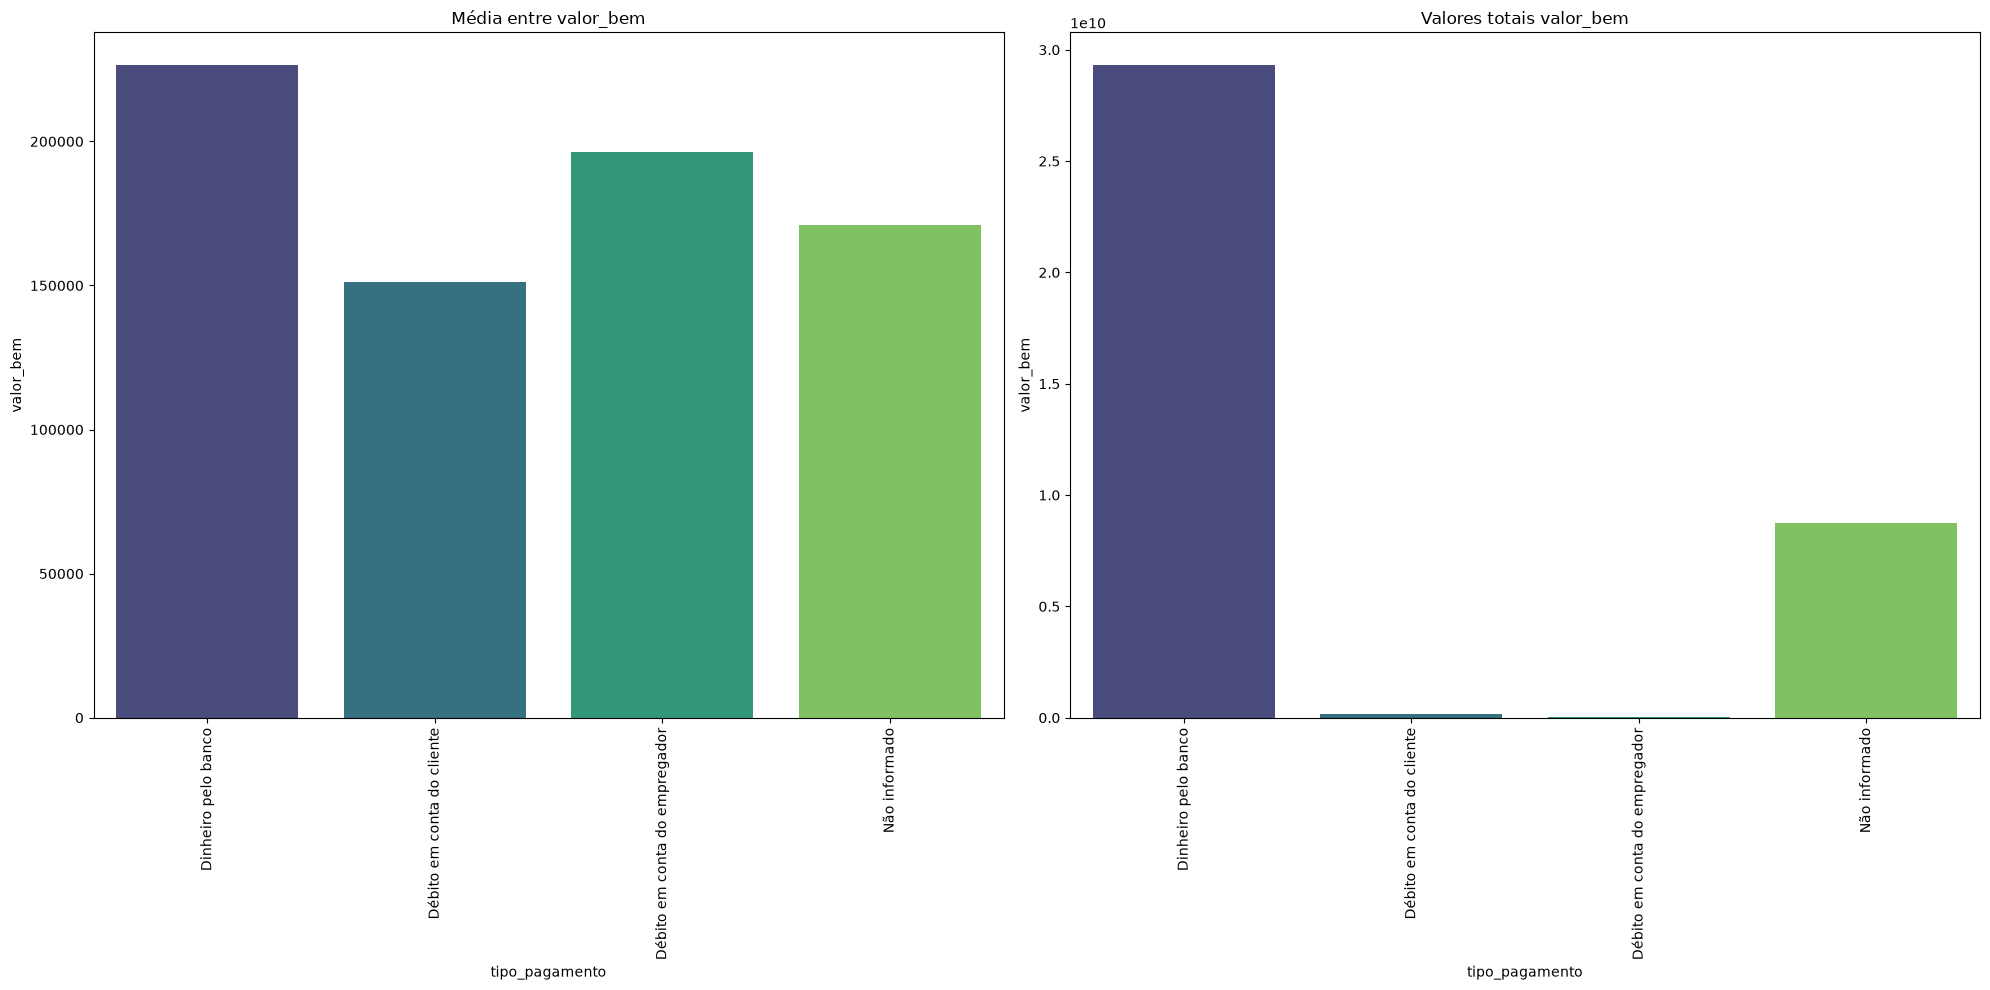

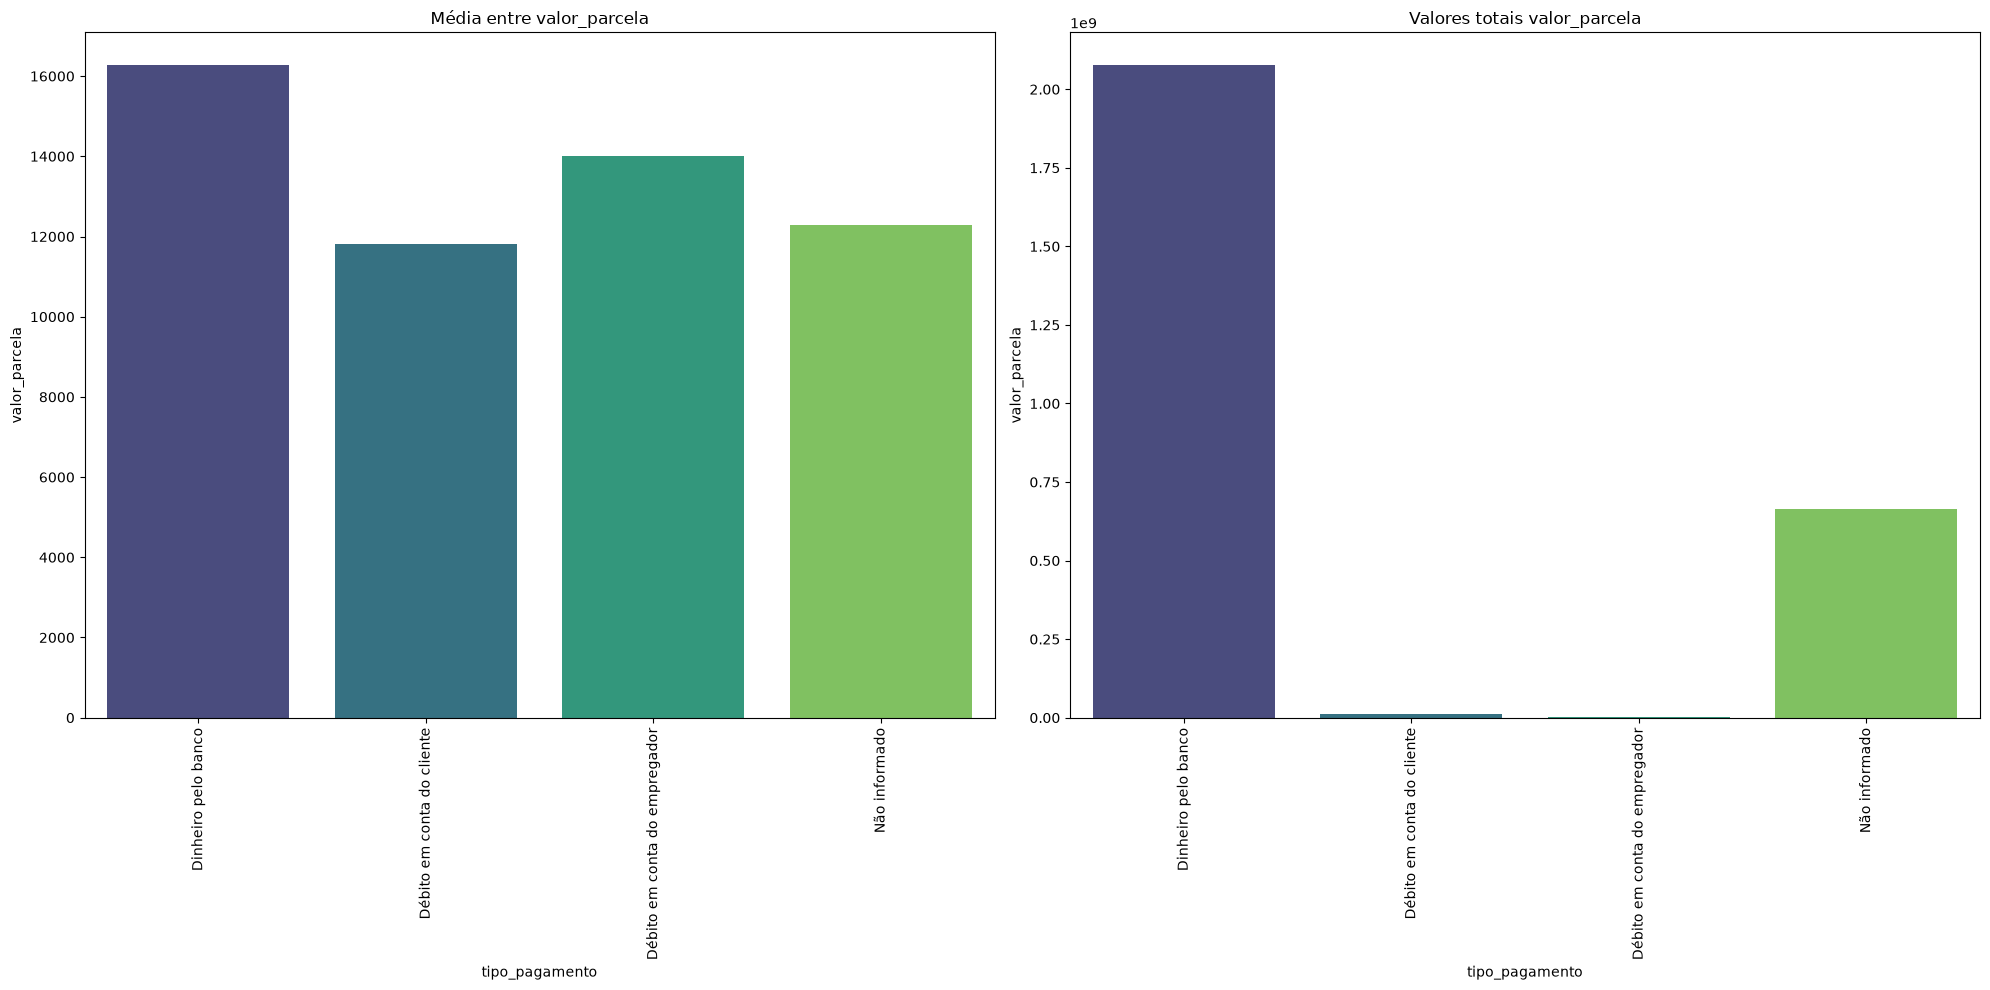

In [33]:
# verificando valores por tipo de pagamento
for num in hue_num_cols:
    print(num)
    PlotGroupby(df_emp, 'tipo_pagamento', f'{num}', f'{num}').plot_mean()
    print()

# Carregando Query de cadastros e emprestimos

In [34]:
query_path = os.path.join('..', 'src', 'analytics', 'cad_emprestimos.sql')
df_cad_emp = read_load_query(query_path)

sexo           tipo_contrato           
feminino       Crédito rotativo            47.509695
               Empréstimo em dinheiro      46.728929
               financiamento de consumo    46.697531
masculino      Crédito rotativo            44.291045
               Empréstimo em dinheiro      44.780000
               financiamento de consumo    44.640000
não informado  Crédito rotativo            56.000000
Name: idade, dtype: float64


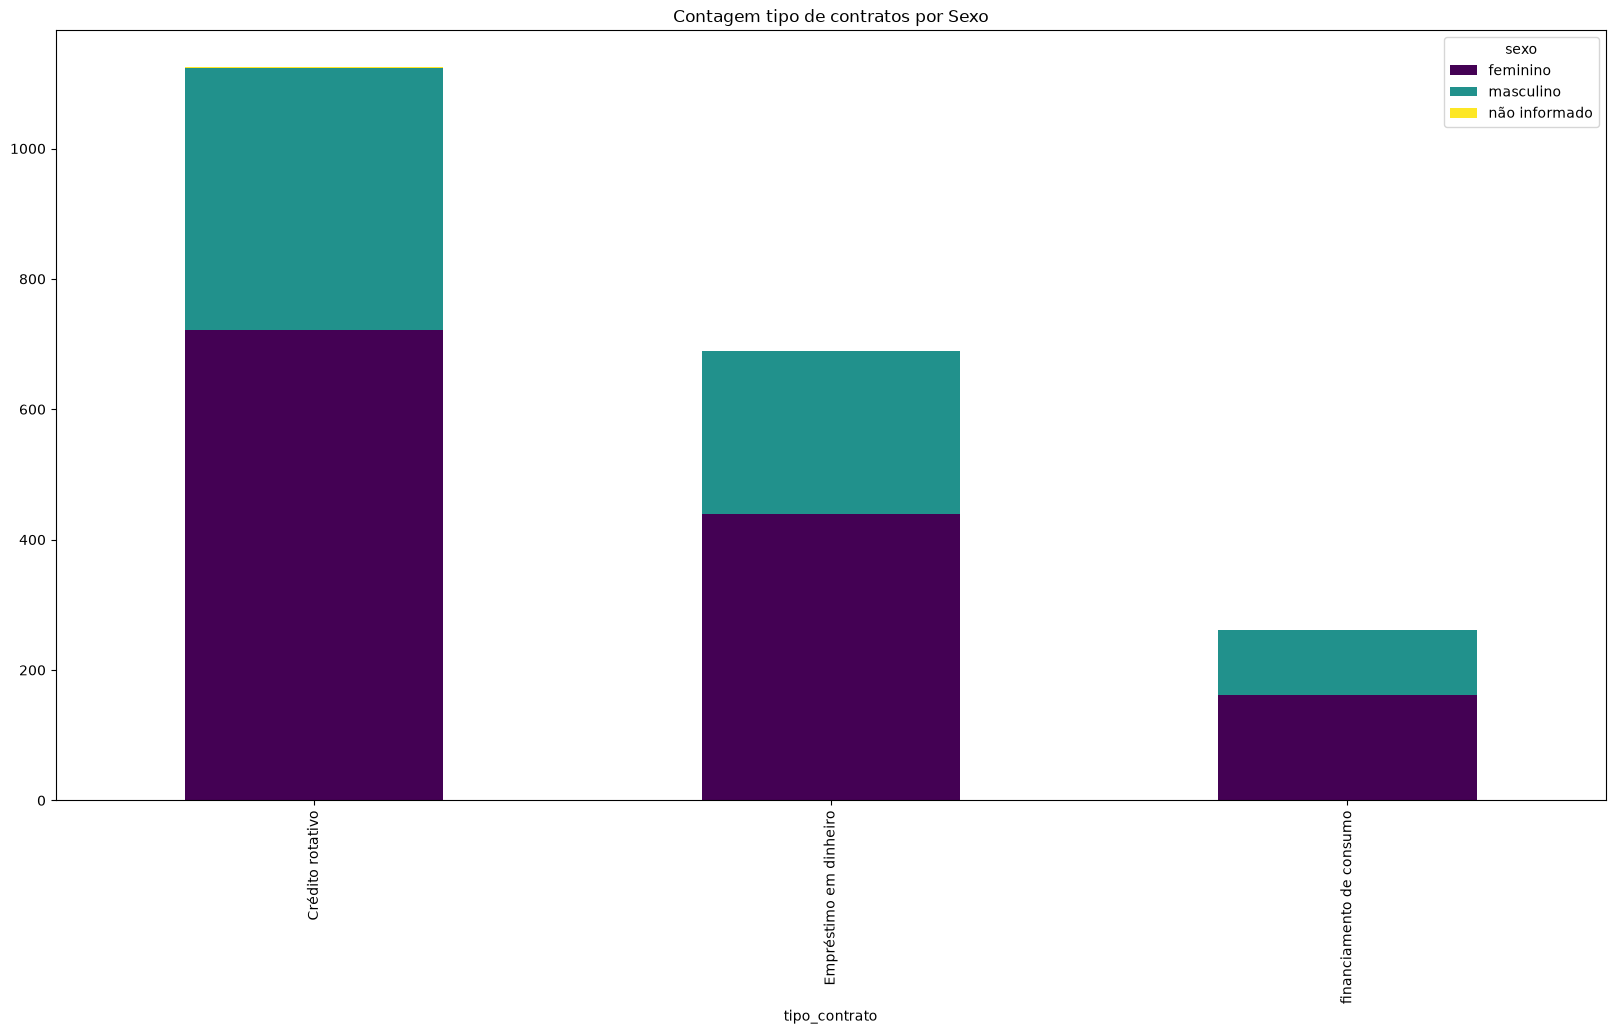

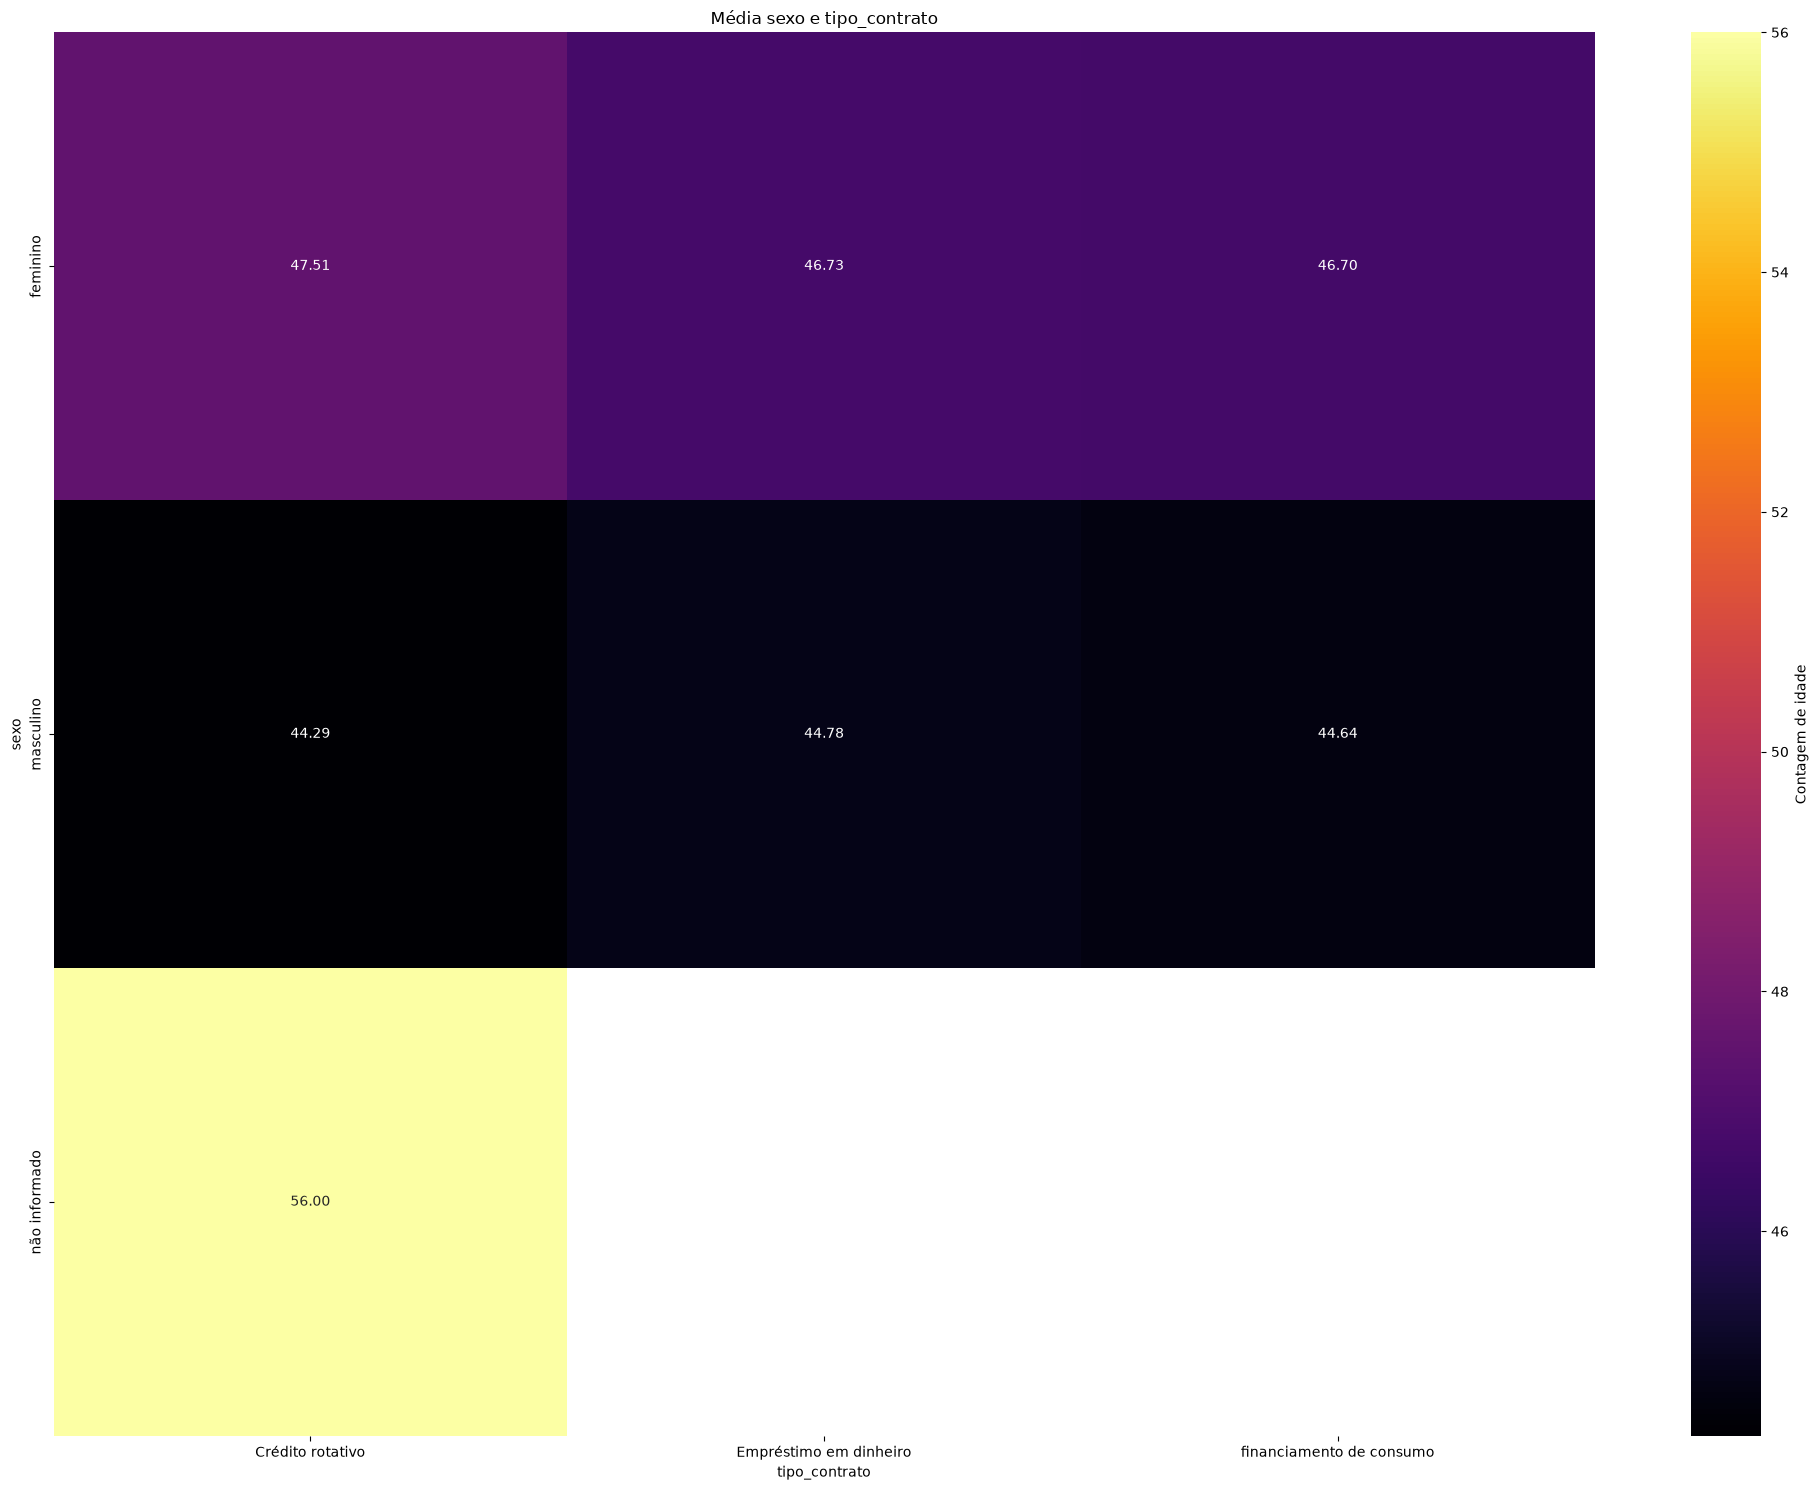

In [35]:
# Contagem tipo de contratos por Sexo
PlotGroupby(df_cad_emp, 'sexo', 'tipo_contrato', 'Contagem tipo de contratos por Sexo').groupby_plot_bar('idade')

In [36]:
df_cad_emp.head()

,id_cliente,sexo,idade,qtd_filhos,possui_imovel,possui_carro,renda_anual,tipo_contrato,valor_credito,valor_parcela,qtd_parcelas_planejadas,finalidade_emprestimo,categoria_bem
0,102358,feminino,43.0,0,não,não,0.0,Crédito rotativo,60435.00,7479.405,12.0,Não se aplica,Não informado
1,459202,masculino,53.0,0,sim,não,16500.0,Crédito rotativo,75193.57,NaN,12.0,Não informado,Não informado
2,458872,feminino,47.0,1,sim,não,20000.0,Crédito rotativo,21192.53,NaN,12.0,Não se aplica,Não informado
3,458538,masculino,31.0,0,sim,não,23000.0,Empréstimo em dinheiro,57297.26,2811.230,24.0,Não se aplica,Eletrônicos de consumo
4,462156,masculino,52.0,0,não,não,24000.0,financiamento de consumo,469914.44,9445.320,12.0,Não informado,Eletrônicos de consumo


sexo           finalidade_emprestimo          
feminino       Casamento, presente ou feriado     49.000000
               Compra de carro usado              24.500000
               Construção de casa ou anexo        58.000000
               Educação                           34.500000
               Móveis                             60.000000
               Necessidades urgentes              51.000000
               Não informado                      48.900000
               Não se aplica                      46.390012
               Outro                              44.470588
               Pagamento de outros empréstimos    56.000000
               Reformas                           46.700000
               Reparo de veículo                  39.500000
               Saúde                              34.000000
masculino      Despesas do dia a dia              30.500000
               Gás ou abastecimento de água       60.000000
               Necessidades urgentes              51.

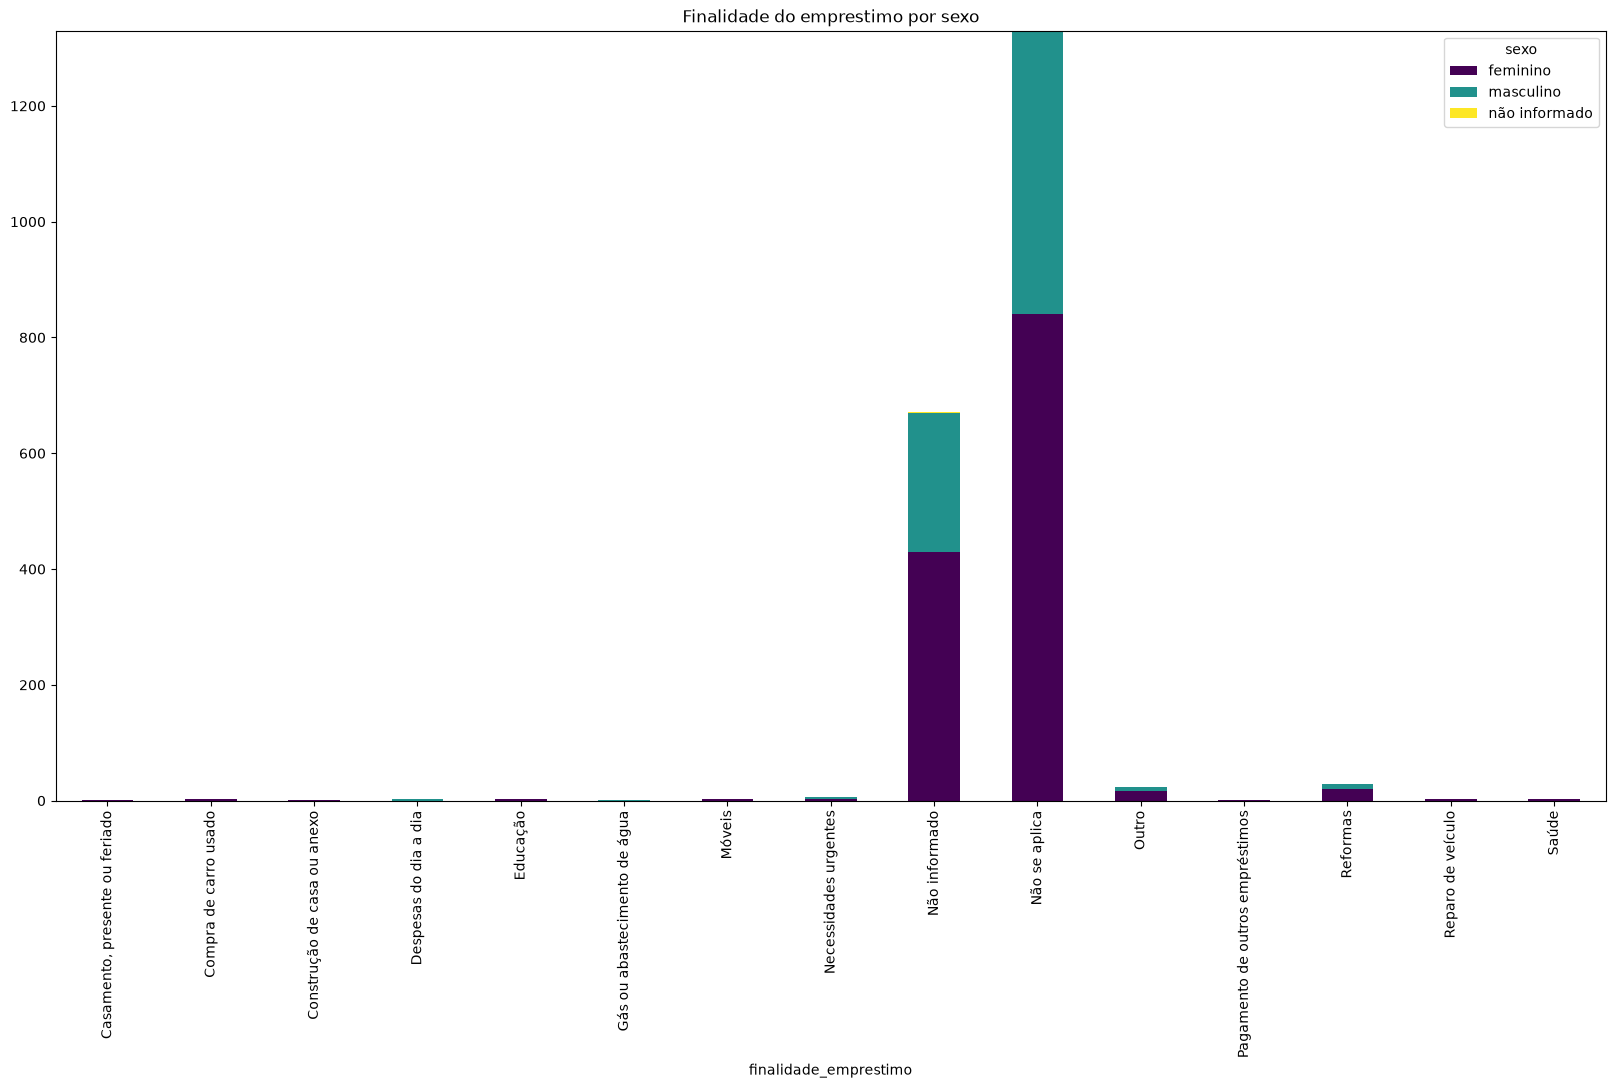

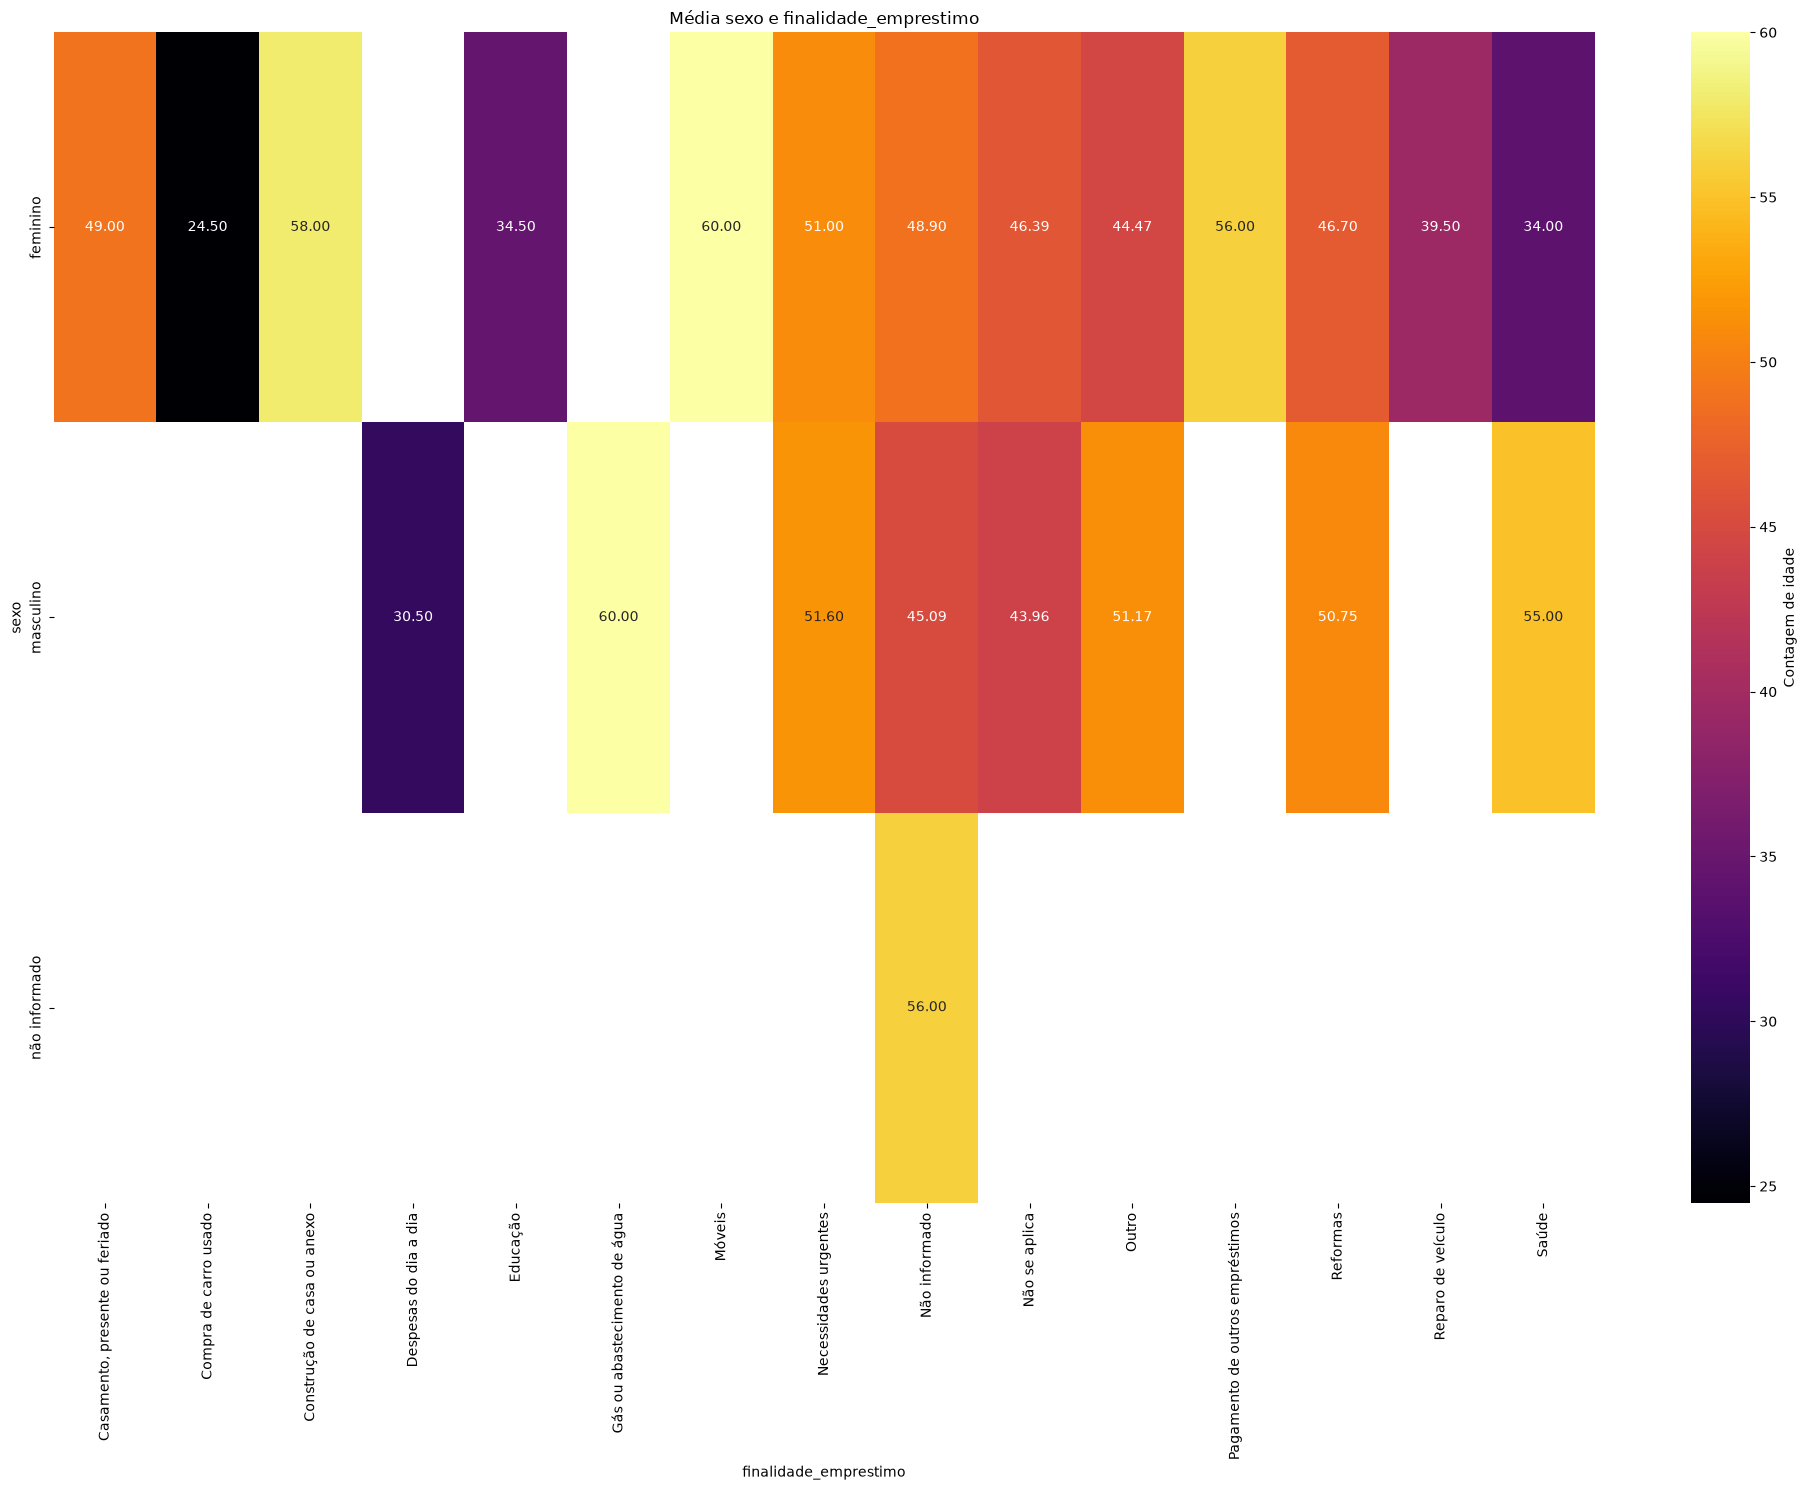

In [37]:
# Finalidade do emprestimo por sexo
PlotGroupby(df_cad_emp, 'sexo', 'finalidade_emprestimo', 'Finalidade do emprestimo por sexo').groupby_plot_bar('idade')

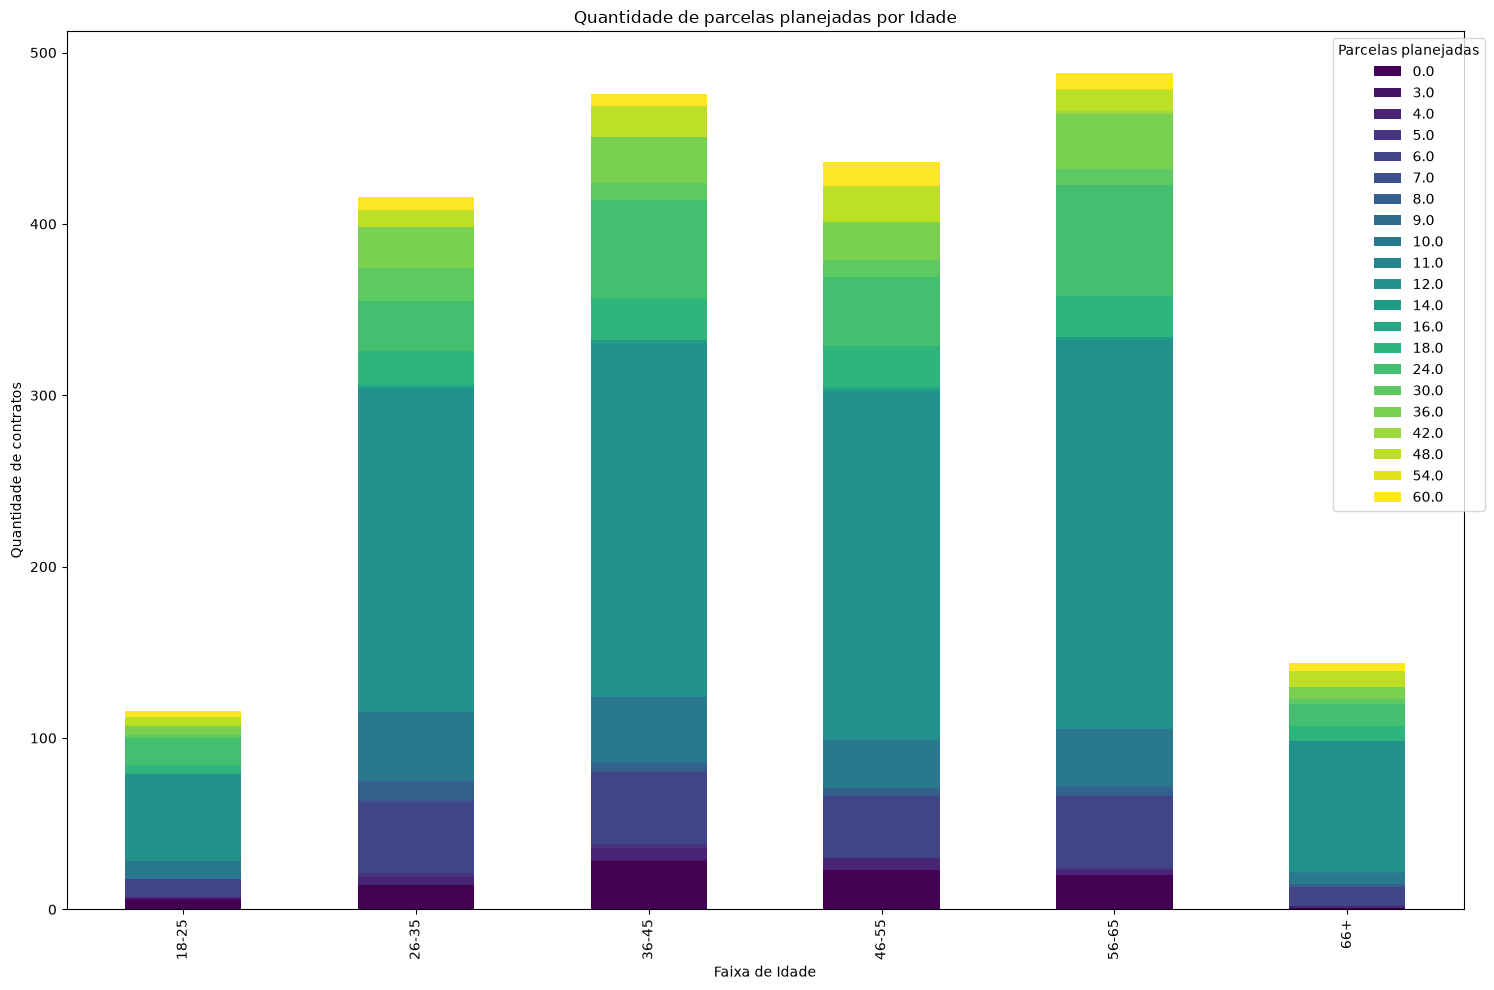

In [38]:
# criando faixa de idade 
cut_idade = [18, 25, 35, 45, 55, 65, 100]
labels = ['18-25', '26-35', '36-45', '46-55', '56-65', '66+']
df_cad_emp['faixa_idade'] = pd.cut(df_cad_emp['idade'], labels=labels, bins=cut_idade)
pd.crosstab(df_cad_emp['faixa_idade'], df_cad_emp['qtd_parcelas_planejadas']).plot(kind='bar', stacked=True, figsize=(15,10), colormap='viridis', title='Quantidade de parcelas planejadas por Idade')
plt.xlabel('Faixa de Idade')
plt.ylabel('Quantidade de contratos')
plt.legend(title='Parcelas planejadas', bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()


# Tabela Parcelas

In [39]:
# carregando base de parcelas
df_parcelas = LoadSQLTable().load_parcelas()
df_parcelas = df_parcelas.set_index(['id_cliente', 'id_contrato'])

In [40]:
df_parcelas.head()

,,versao_parcela,numero_parcela,data_prevista_pagamento,data_real_pagamento,valor_previsto_parcela,valor_pago_parcela,dias_atraso,TARGET
id_cliente,id_contrato,,,,,,,,
100193,1594684,0.0,56,2021-12-21 00:00:00,2021-12-21 00:00:00,301.86,301.86,0.0,0
134723,1995642,1.0,38,2021-08-09 00:00:00,2021-08-04 00:00:00,12949.20,12949.20,-5.0,0
176364,1720935,1.0,9,2024-03-06 00:00:00,2024-03-04 00:00:00,61192.53,61192.53,-2.0,0
154898,1439208,1.0,20,2024-08-11 00:00:00,2024-08-07 00:00:00,8851.23,8851.23,-4.0,0
172575,1640082,1.0,4,2022-11-15 00:00:00,2022-11-10 00:00:00,8720.28,8720.28,-5.0,0


In [41]:
print('Event rate:', round(df_parcelas['TARGET'].mean(),3)*100,'%')


Event rate: 1.5 %


In [42]:
num_col_parcelas = df_parcelas.select_dtypes(include='number')
num_col_parcelas.describe().T

,count,mean,std,min,25%,50%,75%,max
versao_parcela,1664384.0,0.808455,1.020606,0.0,0.00,1.000,1.000,5.200000e+01
numero_parcela,1664384.0,14.227688,19.413296,1.0,4.00,8.000,16.000,1.940000e+02
valor_previsto_parcela,1664384.0,17197.891083,48839.035730,0.0,3974.22,8841.465,17296.065,2.784334e+06
valor_pago_parcela,1660732.0,17536.786289,53920.559223,0.0,3375.00,8186.400,16729.155,6.556919e+06
dias_atraso,1660729.0,-6.967774,22.941974,-917.0,-13.00,-4.000,0.000,2.290000e+03
TARGET,1664384.0,0.014726,0.120452,0.0,0.00,0.000,0.000,1.000000e+00


# Segmentação de perfis de clientes

In [43]:
cluster_query = os.path.join('..', 'src', 'analytics', 'seguimentacao_contratos.sql')
data_cluster = read_load_query(cluster_query)
data_cluster = data_cluster.set_index('id_contrato')

In [44]:
# dropando 13 registros nulos de media dias de atraso
data_cluster = data_cluster.dropna()

In [45]:
data_cluster.head()

,freq_contratos,media_valor_parcela,media_dias_atrasos,numero_max_parcelas
id_contrato,,,,
1000003,3,4951.35,-15.0,3
1000013,13,13337.87,-5.0,12
1000019,13,6067.20,-13.0,12
1000053,7,5706.53,-7.0,6
1000056,8,4570.42,-26.0,8


treinando cluster 2
davies_b_score: 0.4555018133319853 | inertia: 213626463012422.06

treinando cluster 3
davies_b_score: 0.46693474874047786 | inertia: 110435621925897.16

treinando cluster 4
davies_b_score: 0.47641236904789375 | inertia: 68513133668869.125

treinando cluster 5
davies_b_score: 0.49173841415006436 | inertia: 45826173170139.83

treinando cluster 6
davies_b_score: 0.500610519259535 | inertia: 33743663687691.25

treinando cluster 7
davies_b_score: 0.5182603104024529 | inertia: 25928578302880.094

treinando cluster 8
davies_b_score: 0.5086145881535082 | inertia: 20773471305705.4

treinando cluster 9
davies_b_score: 0.48197212719747173 | inertia: 15290771035865.973

treinando cluster 10
davies_b_score: 0.4907650908735529 | inertia: 12947845151292.225



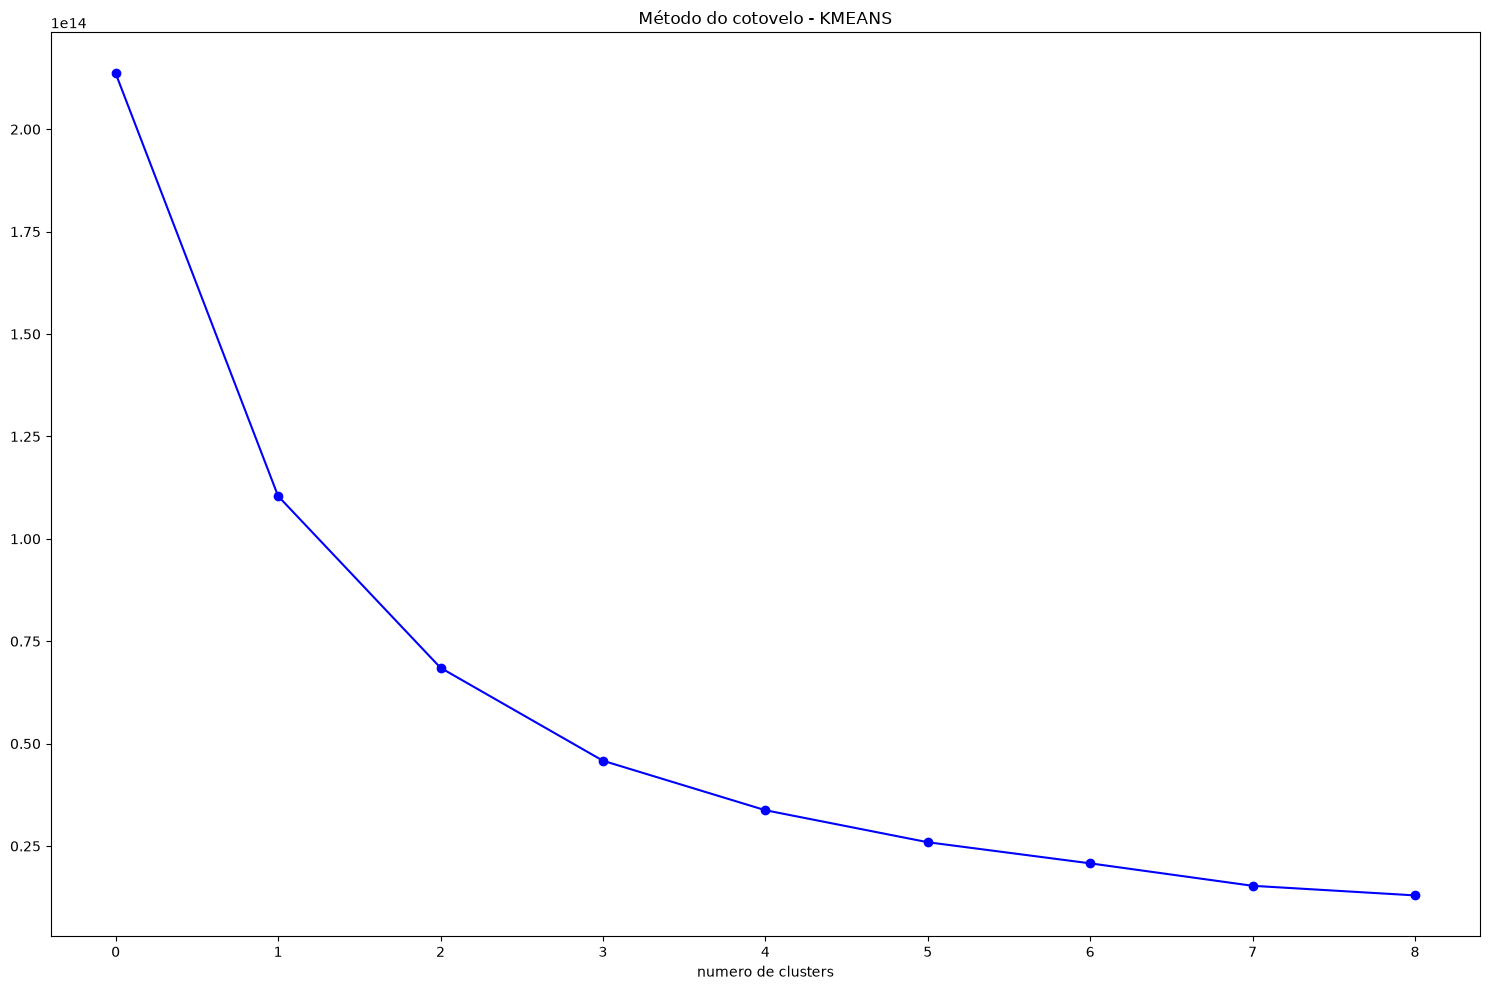

In [46]:
# Teste do Cotovelo
inertia = []
for i in range(2,11):
    print(f'treinando cluster {i}')
    kmeans_model = KMeans(max_iter=10000, n_clusters=i).fit(data_cluster)
    davies_b = davies_bouldin_score(data_cluster, kmeans_model.labels_)
    print(f'davies_b_score: {davies_b} | inertia: {kmeans_model.inertia_}')
    inertia.append(kmeans_model.inertia_)
    print()
plt.figure(figsize=(15,10))
plt.title('Método do cotovelo - KMEANS')
plt.plot(inertia, marker='o', color='blue')
plt.xlabel('numero de clusters')
plt.tight_layout()
plt.show()

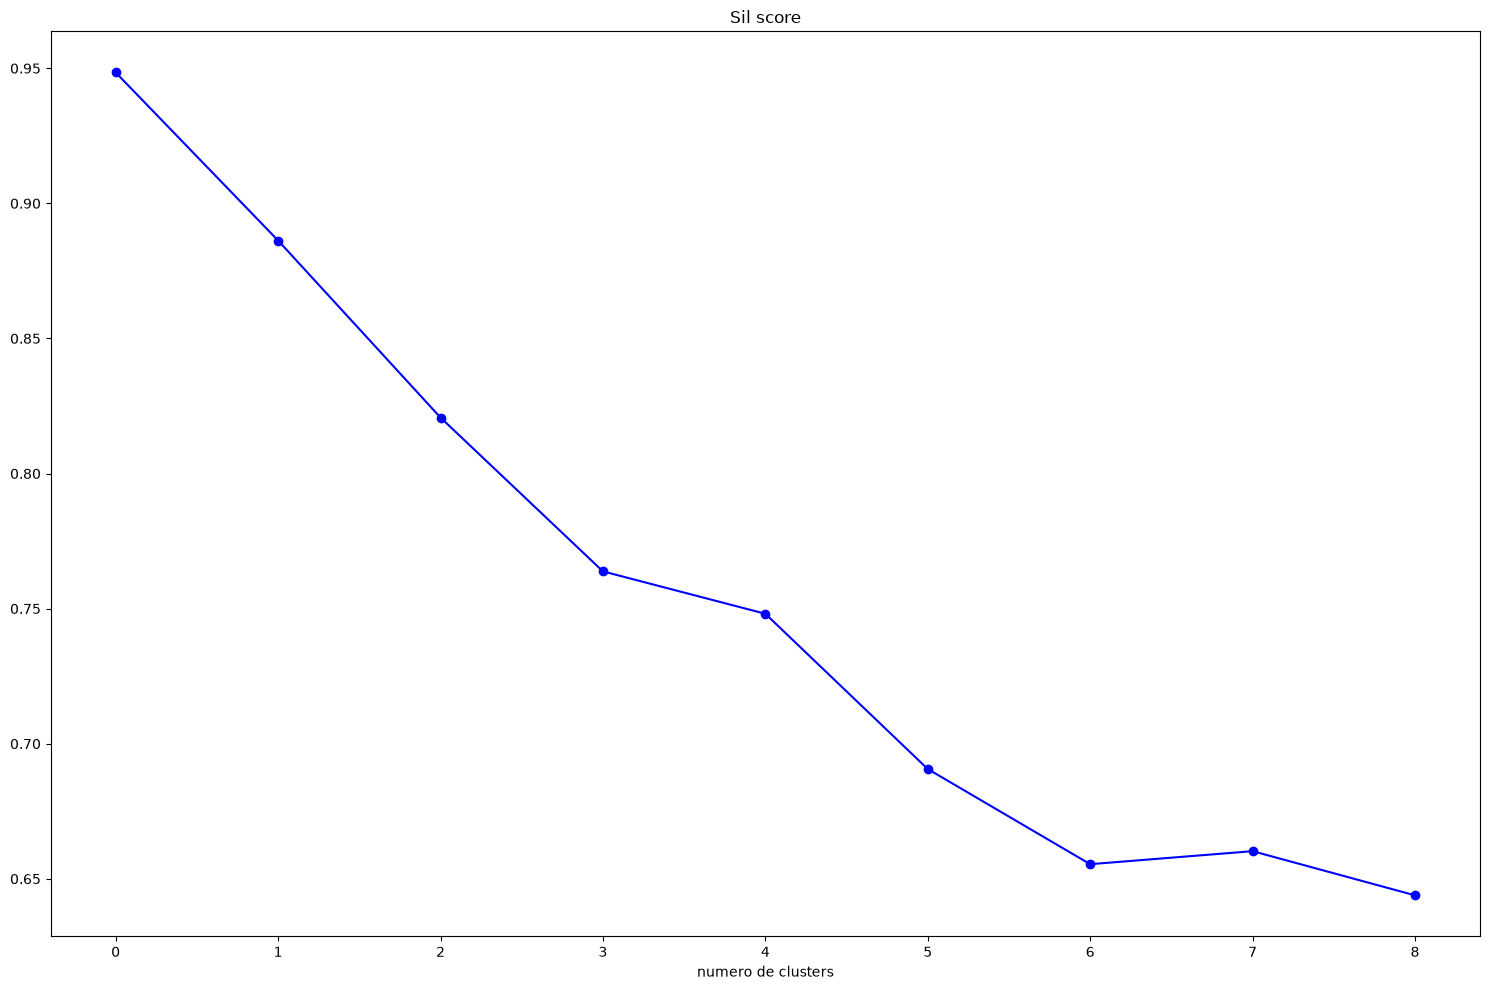

In [47]:
# teste da Sillhueta
n_sample = min(7000, len(data_cluster))
sil_score = []
for i in range(2,11):
    kmeans_model = KMeans(n_clusters=i, max_iter=10000).fit(data_cluster)
    sil = silhouette_score(data_cluster, kmeans_model.labels_, sample_size=n_sample)
    sil_score.append(sil)
plt.figure(figsize=(15,10))
plt.title('Sil score')
plt.plot(sil_score, marker='o', color='blue')
plt.xlabel('numero de clusters')
plt.tight_layout()
plt.show()

- O numero ideal de clusters (graficamente) esta entre 2 e 3 grupos

In [48]:
kmeans_model = KMeans(n_clusters=3, max_iter=10000)
data_cluster['cluster'] = kmeans_model.fit_predict(data_cluster)

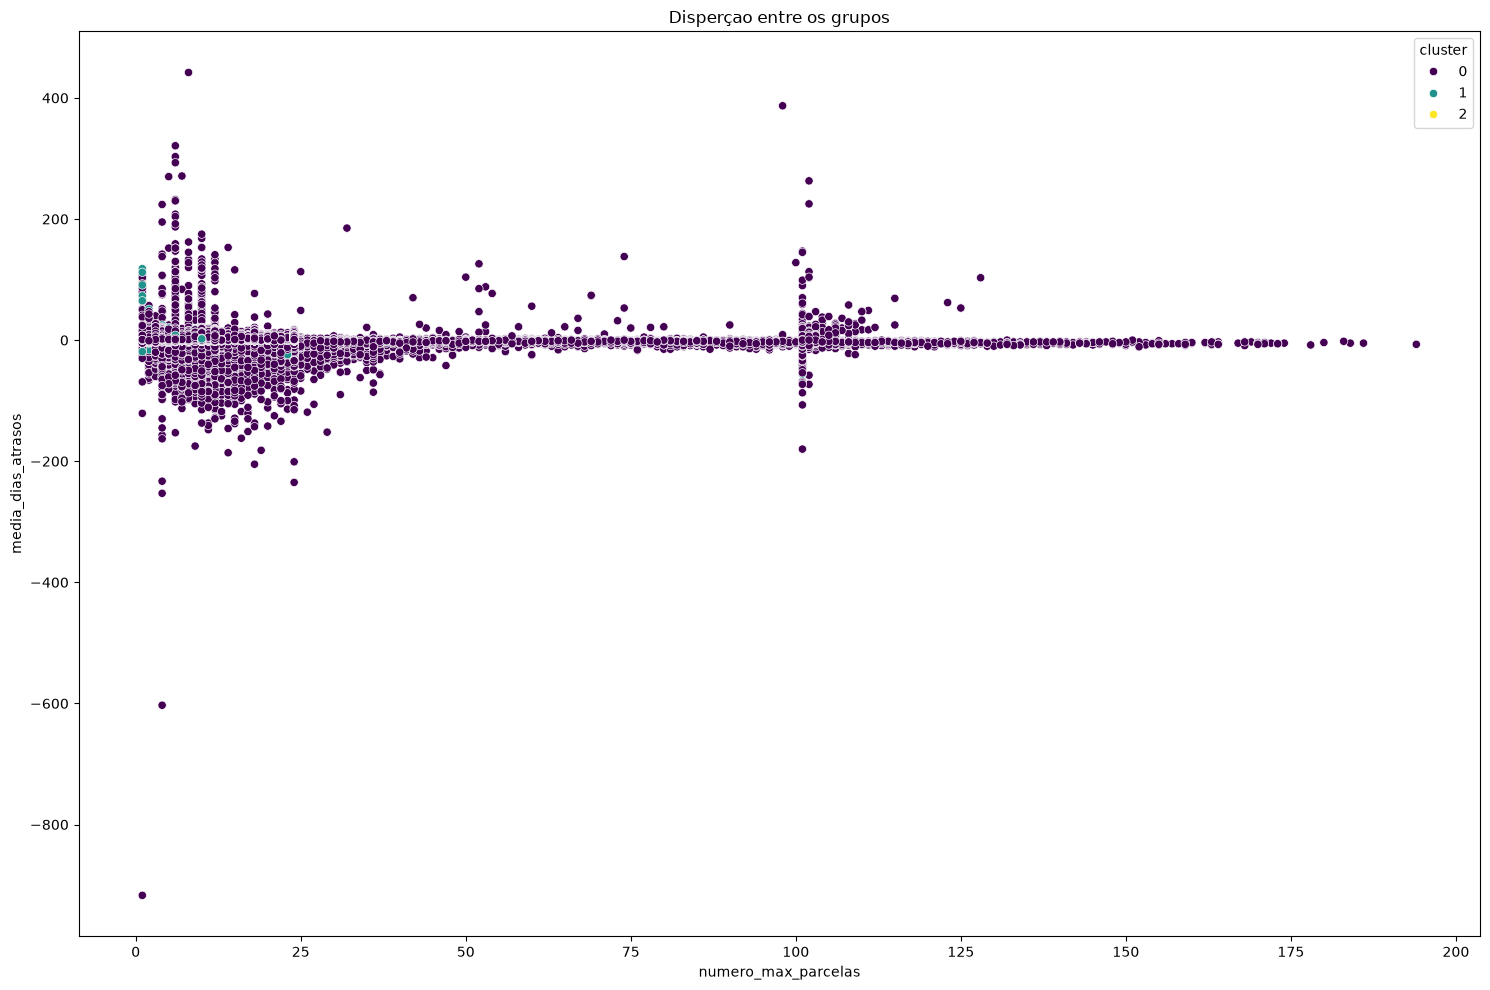

In [49]:
plt.figure(figsize=(15,10))
plt.title('Disperçao entre os grupos')
sns.scatterplot(data=data_cluster, x='numero_max_parcelas', y='media_dias_atrasos', hue='cluster', palette='viridis')
plt.tight_layout()
plt.show()

In [50]:
# frequencia de cada grupo
data_cluster['cluster'].value_counts(normalize=True)

cluster
0    0.969989
1    0.027936
2    0.002076
Name: proportion, dtype: float64

In [51]:
# qual grupo possui maior média de atrasados? 
cluster_agg = ['media_dias_atrasos', 'freq_contratos', 'media_valor_parcela', 'numero_max_parcelas']
for i in cluster_agg:
    print(f'média {i} e grupos')
    display(data_cluster.groupby('cluster')[f'{i}'].agg(['mean', 'median','std', 'count', 'max', 'min']))
    print('---'*50)

média media_dias_atrasos e grupos


,mean,median,std,count,max,min
cluster,,,,,,
0,-9.552703,-8.0,13.527695,119167,442.0,-917.0
1,-8.767774,-8.0,11.288768,3432,118.0,-94.0
2,-9.674510,-9.0,10.423698,255,97.0,-29.0


------------------------------------------------------------------------------------------------------------------------------------------------------
média freq_contratos e grupos


,mean,median,std,count,max,min
cluster,,,,,,
0,13.818473,10.0,14.373326,119167,196,1
1,5.044580,4.0,4.453005,3432,59,1
2,1.231373,1.0,0.537379,255,4,1


------------------------------------------------------------------------------------------------------------------------------------------------------
média media_valor_parcela e grupos


,mean,median,std,count,max,min
cluster,,,,,,
0,17281.231231,10840.60,18807.171706,119167,117602.83,0.45
1,217782.190288,179068.46,105157.528115,3432,603803.97,117638.35
2,990802.872235,910596.60,345449.951531,255,2297388.78,605987.65


------------------------------------------------------------------------------------------------------------------------------------------------------
média numero_max_parcelas e grupos


,mean,median,std,count,max,min
cluster,,,,,,
0,13.943667,10.0,16.424886,119167,194,1
1,4.879079,3.0,5.590224,3432,103,1
2,1.211765,1.0,0.488307,255,4,1


------------------------------------------------------------------------------------------------------------------------------------------------------


Diferenças entre os grupos (antes do teste de Hipoteses): 
- o grupo 0 é o grupo que menos atrasa, o grupo 1 é de atrasos médios, e o 2 é o que mais costuma atrasar
- o grupo 0 é o grupo mais frequente entre os contratos, o 2 tambem é frequente, mas ainda numa frequencia menor
- o grupo 1 tem média de valor de parcela maior, o desvio também é bem grande. Porem, aparece numa frequencia menor, indicando comportamento de cliente raro 
- o grupo 0 tende a ter um range maior de parcelas, devido tambem a menores valores de parcela. O grupo 1 tende a ter um numero menor de parcelas 

# Teste de Hipoteses

A partir das afirmações dadas a diferenças entre grupo, irei trabalhar com teste de hipoteses para validar ou nao estatisticamente as afirmaçoes acima

As Hipoteses terão essa cara: 

H0: Não há diferença entre os grupos 
H1: Há diferença entre os grupos

In [52]:
data_cluster.head()

,freq_contratos,media_valor_parcela,media_dias_atrasos,numero_max_parcelas,cluster
id_contrato,,,,,
1000003,3,4951.35,-15.0,3,0
1000013,13,13337.87,-5.0,12,0
1000019,13,6067.20,-13.0,12,0
1000053,7,5706.53,-7.0,6,0
1000056,8,4570.42,-26.0,8,0


In [53]:
# teste de hipoteses para as diferenças entre os cluester e caracteristicas de seguimentação
for ttest in cluster_agg:
    _, p_value = stats.mannwhitneyu(data_cluster[f'{ttest}'], data_cluster['cluster'])
    print(f'teste: diferença entre {ttest} e Cluster' )
    if p_value <0.05:
        print(f'H0 rejeitada: há diferença entre os grupos | p_valor: {p_value}')
        print()
    else:
        print(f'Aceite H0: não há diferença entre os grupos | p_valor: {p_value}')
        print()

teste: diferença entre media_dias_atrasos e Cluster
H0 rejeitada: há diferença entre os grupos | p_valor: 0.0

teste: diferença entre freq_contratos e Cluster
H0 rejeitada: há diferença entre os grupos | p_valor: 0.0

teste: diferença entre media_valor_parcela e Cluster
H0 rejeitada: há diferença entre os grupos | p_valor: 0.0

teste: diferença entre numero_max_parcelas e Cluster
H0 rejeitada: há diferença entre os grupos | p_valor: 0.0



# Defaults por cadastro do cliente

In [55]:
query_cliente_default = os.path.join('..', 'src', 'analytics', 'cliente_default.sql')
df_cliente_default = read_load_query(query_cliente_default)

In [ ]:
df_cliente_default = df_cliente_default.set_index(['id_contrato', 'id_cliente'])


KeyError: "None of ['id_contrato', 'id_cliente'] are in the columns"

In [61]:
df_cliente_default.sample(5)

,,sexo,qtd_filhos,qtd_membros_familia,renda_anual,estado_civil,idade,nivel_educacao,possui_carro,possui_imovel,TARGET,dias_atraso,valor_previsto_parcela,valor_pago_parcela
id_contrato,id_cliente,,,,,,,,,,,,,
1610882.0,310840,masculino,0,2.0,234000.0,Casado,51.0,Ensino superior incompleto,sim,não,0.0,-85.0,8856.180,46.800000
1724080.0,231344,feminino,0,1.0,202500.0,Separado,50.0,Ensino médio,não,sim,0.0,0.0,357.345,294.248446
2865984.0,464486,masculino,0,1.0,364500.0,Casado,69.0,Ensino médio,não,sim,0.0,-2.0,14339.110,14339.110000
1605106.0,250430,masculino,2,4.0,315000.0,Casado,42.0,Ensino médio,sim,sim,0.0,0.0,6750.000,6750.000000
2110658.0,278977,masculino,2,4.0,315000.0,Casado,43.0,Ensino médio,sim,sim,0.0,-29.0,27784.305,13134.690000


In [65]:
# verificando percentual de inadimplentes por sexo 
df_cliente_default.groupby('sexo')['TARGET'].agg(['mean', 'count']).sort_values('mean', ascending=False)

,mean,count
sexo,,
masculino,0.015983,536944
feminino,0.014163,1112247
não informado,0.009615,1456


In [104]:
num_client_default = df_cliente_default.select_dtypes(include='number')
cat_client_default = df_cliente_default.select_dtypes(exclude='number').columns

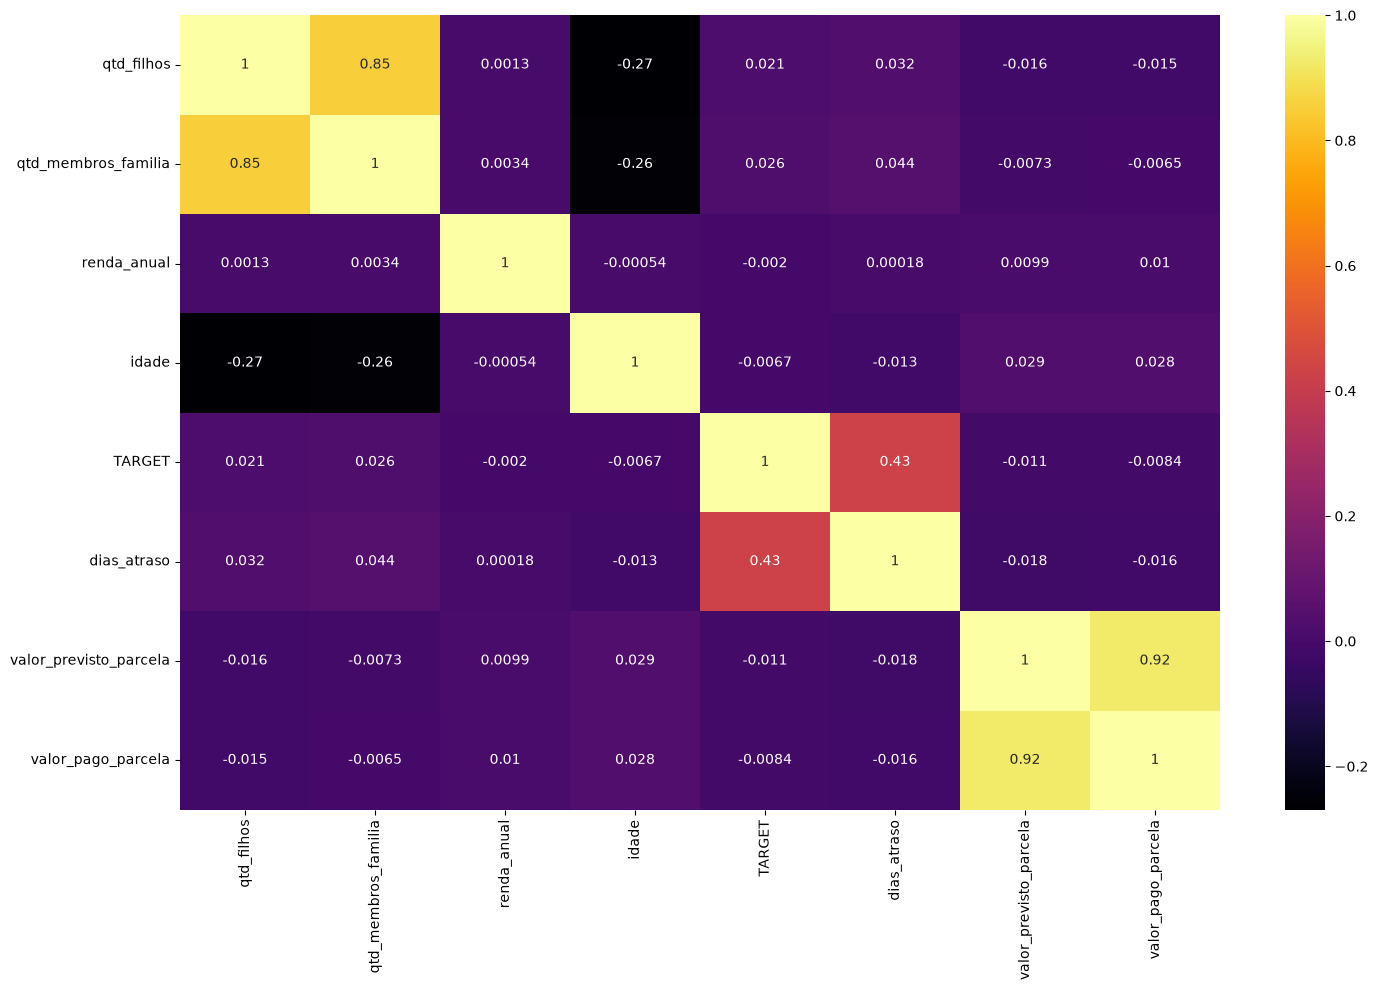

In [74]:
plt.figure(figsize=(15,10))
sns.heatmap(num_client_default.corr(), annot=True, cmap='inferno')
plt.tight_layout()
plt.show()

- Podemos observar pouca relaçao linear. Apenas variaveis derivadas uma da outra apresentam relaçao linear forte

In [ ]:
# porcentagem de inadimplentes por quantidade de filhos
df_cliente_default.groupby('qtd_filhos')['TARGET'].agg(['mean', 'count']).sort_values('mean', ascending=False)

,mean,count
qtd_filhos,,
4,0.038873,8129
5,0.034169,2634
6,0.030651,783
3,0.028770,29475
2,0.017772,152877
1,0.015457,315645
0,0.013565,1140705
7,0.005525,181
8,0.000000,165


In [79]:
df_cliente_default

sexo  qtd_filhos  qtd_membros_familia  \
id_contrato id_cliente                                               
1131053.0   100023       feminino           1                  2.0   
            100023       feminino           1                  2.0   
            100023       feminino           1                  2.0   
            100023       feminino           1                  2.0   
            100023       feminino           1                  2.0   
...                           ...         ...                  ...   
2378948.0   213846      masculino           1                  3.0   
            213846      masculino           1                  3.0   
            213846      masculino           1                  3.0   
            213846      masculino           1                  3.0   
NaN         317001       feminino           0                  2.0   

                        renda_anual estado_civil  idade   nivel_educacao  \
id_contrato id_cliente                                                     
1131053.0   100023         90000.00     Solteiro   32.0  Ensino superior   
            100023         90000.00     Solteiro   32.0  Ensino superior   
            100023         90000.00     Solteiro   32.0  Ensino superior   
            100023         90000.00     Solteiro   32.0  Ensino superior   
            100023         90000.00     Solteiro   32.0  Ensino superior   
...                             ...          ...    ...              ...   
2378948.0   213846        164369.16       Casado   31.0     Ensino médio   
            213846        164369.16       Casado   31.0     Ensino médio   
            213846        164369.16       Casado   31.0     Ensino médio   
            213846        164369.16       Casado   31.0     Ensino médio   
NaN         317001        190906.12       Casado   24.0     Ensino médio   

                       possui_carro possui_imovel  TARGET  dias_atraso  \
id_contrato id_cliente                                                   
1131053.0   100023              não           sim     0.0        -26.0   
            100023              não           sim     0.0        -24.0   
            100023              não           sim     0.0          0.0   
            100023              não           sim     0.0          0.0   
            100023              não           sim     0.0          0.0   
...                             ...           ...     ...          ...   
2378948.0   213846              sim           sim     0.0        -16.0   
            213846              sim           sim     0.0        -12.0   
            213846              sim           sim     0.0        -12.0   
            213846              sim           sim     0.0        -14.0   
NaN         317001              sim           sim     NaN          NaN   

                        valor_previsto_parcela  valor_pago_parcela  
id_contrato id_cliente                                              
1131053.0   100023                     8519.13             8519.13  
            100023                     8519.13             8519.13  
            100023                     8519.13             8519.13  
            100023                     8519.13             8519.13  
            100023                     8519.13             8519.13  
...                                        ...                 ...  
2378948.0   213846                     3757.68             3757.68  
            213846                     3757.68             3757.68  
            213846                     3757.68             3757.68  
            213846                     7285.41             7285.41  
NaN         317001                         NaN                 NaN  

[1654380 rows x 13 columns]

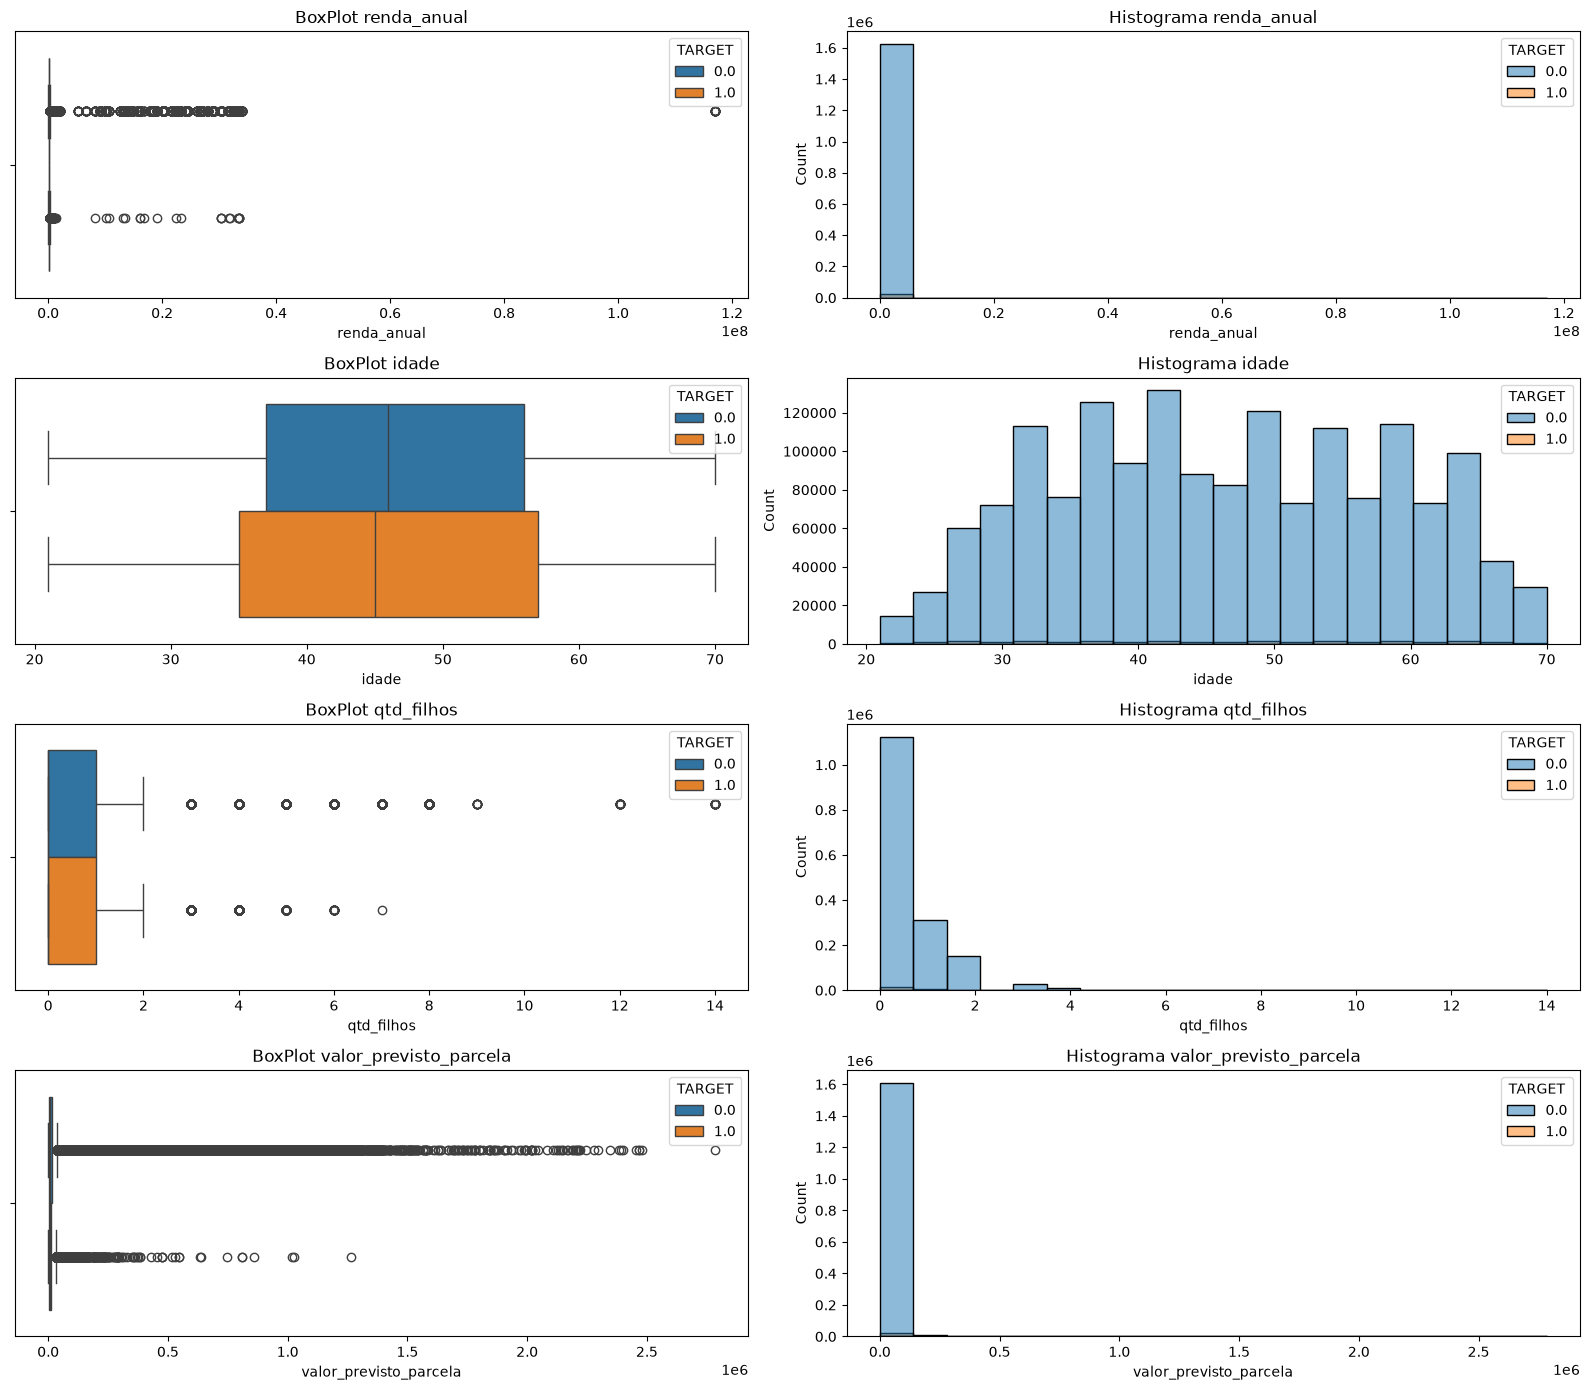

In [ ]:
target_num_cols = ['renda_anual', 'idade', 'qtd_filhos', 'valor_previsto_parcela']
fig, axes = plt.subplots(nrows=len(target_num_cols), ncols=2, figsize=(16, 3.5 * len(target_num_cols)))
for i, num in enumerate(target_num_cols):
    sns.boxplot(data=df_cliente_default.reset_index(drop=True), x=num, hue='TARGET', ax=axes[i,0])
    sns.histplot(data=df_cliente_default.reset_index(drop=True), x=num, hue='TARGET', ax=axes[i,1], bins=20)
    axes[i,0].set_title(f'BoxPlot {num}')
    axes[i,1].set_title(f'Histograma {num}')
fig.tight_layout()
fig.show()

In [ ]:
# idade que mais fica inadimplente (10 idaades que mais fica inadimplentes)
df_cliente_default.groupby('idade')['TARGET'].agg(['mean', 'count']).sort_values('mean', ascending=False).head(10)

,mean,count
idade,,
22.0,0.046363,5651
21.0,0.040000,950
23.0,0.039832,8812
25.0,0.028745,14333
24.0,0.028087,13209
26.0,0.027119,16999
68.0,0.023069,14565
69.0,0.022193,13743
67.0,0.022126,19163


- Podemos ver que jovens apresentam maior proporçao entre os inadimplentes. Podemos tambem observar a presença de alguns clientes com idade acima de 60 anos que tambem são propicios a inadimplencia

Teste de diferença entre grupos - Idade X inadimplência

In [ ]:
_, p_value = stats.mannwhitneyu(df_cliente_default['idade'].dropna(), df_cliente_default['TARGET'].dropna())
if p_value < 0.05:
    print(f'Rejeita H0: há diferença entre a idade e inadimplência | pvalue: {p_value}')
else:
    print(f'Aceita H0: Não há diferença entre os grupos | pvalue: {p_value}')

Rejeita H0: há diferença entre a idade e inadimplência | pvalue: 0.0


In [106]:
# estado civil com maior percentual de incadimplencia 
df_cliente_default.groupby('estado_civil')['TARGET'].agg(['mean', 'count']).sort_values('mean', ascending=False)

,mean,count
estado_civil,,
Solteiro,0.017869,217417
Não informado,0.017339,4787
Viúvo,0.016555,89699
União estável,0.015602,160620
Separado,0.014691,107209
Casado,0.013834,1070915


In [108]:
# grau de escolaridade com maior percentual de inadimplencia 
df_cliente_default.groupby('nivel_educacao')['TARGET'].agg(['mean', 'count']).sort_values('mean', ascending=False)

,mean,count
nivel_educacao,,
Pós-graduação,0.040072,2221
Ensino fundamental,0.023325,22122
Ensino superior incompleto,0.016363,53841
Ensino superior,0.015620,355885
Ensino médio,0.014224,1216578


In [110]:
df_cliente_default

sexo  qtd_filhos  qtd_membros_familia  \
id_contrato id_cliente                                               
1131053.0   100023       feminino           1                  2.0   
            100023       feminino           1                  2.0   
            100023       feminino           1                  2.0   
            100023       feminino           1                  2.0   
            100023       feminino           1                  2.0   
...                           ...         ...                  ...   
2378948.0   213846      masculino           1                  3.0   
            213846      masculino           1                  3.0   
            213846      masculino           1                  3.0   
            213846      masculino           1                  3.0   
NaN         317001       feminino           0                  2.0   

                        renda_anual estado_civil  idade   nivel_educacao  \
id_contrato id_cliente                                                     
1131053.0   100023         90000.00     Solteiro   32.0  Ensino superior   
            100023         90000.00     Solteiro   32.0  Ensino superior   
            100023         90000.00     Solteiro   32.0  Ensino superior   
            100023         90000.00     Solteiro   32.0  Ensino superior   
            100023         90000.00     Solteiro   32.0  Ensino superior   
...                             ...          ...    ...              ...   
2378948.0   213846        164369.16       Casado   31.0     Ensino médio   
            213846        164369.16       Casado   31.0     Ensino médio   
            213846        164369.16       Casado   31.0     Ensino médio   
            213846        164369.16       Casado   31.0     Ensino médio   
NaN         317001        190906.12       Casado   24.0     Ensino médio   

                       possui_carro possui_imovel  TARGET  dias_atraso  \
id_contrato id_cliente                                                   
1131053.0   100023              não           sim     0.0        -26.0   
            100023              não           sim     0.0        -24.0   
            100023              não           sim     0.0          0.0   
            100023              não           sim     0.0          0.0   
            100023              não           sim     0.0          0.0   
...                             ...           ...     ...          ...   
2378948.0   213846              sim           sim     0.0        -16.0   
            213846              sim           sim     0.0        -12.0   
            213846              sim           sim     0.0        -12.0   
            213846              sim           sim     0.0        -14.0   
NaN         317001              sim           sim     NaN          NaN   

                        valor_previsto_parcela  valor_pago_parcela  
id_contrato id_cliente                                              
1131053.0   100023                     8519.13             8519.13  
            100023                     8519.13             8519.13  
            100023                     8519.13             8519.13  
            100023                     8519.13             8519.13  
            100023                     8519.13             8519.13  
...                                        ...                 ...  
2378948.0   213846                     3757.68             3757.68  
            213846                     3757.68             3757.68  
            213846                     3757.68             3757.68  
            213846                     7285.41             7285.41  
NaN         317001                         NaN                 NaN  

[1654380 rows x 13 columns]

In [111]:
df_cliente_default.groupby('possui_carro')['TARGET'].agg(['mean', 'count']).sort_values('mean', ascending=False)

,mean,count
possui_carro,,
sim,0.014852,553654
não,0.014704,1095298
não informado,0.012389,1695


In [112]:
df_cliente_default.groupby('possui_imovel')['TARGET'].agg(['mean', 'count']).sort_values('mean', ascending=False)

,mean,count
possui_imovel,,
não informado,0.017174,2038
não,0.015039,481144
sim,0.014628,1167465
